# Imports

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
%%shell
pip install pyimagej spectral -qqq

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
%%shell
# apt update # not always this is needed
apt install -y maven > /dev/null

In [ ]:
# !git clone -b development https://github.com/chilly-nk/CubeExplore.git
# %cd CubeExplore

fatal: destination path 'CubeExplore' already exists and is not an empty directory.
/content/CubeExplore


In [ ]:
# Import cubexplore and its functions or classes

import cubexplore as cubex
from cubexplore import Cubes

cubex.__version__

'1.0'

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import spectral as spy

from pathlib import Path

%config InlineBackend.figure_format = 'retina' # to make plots appear nicer on some screens

# Functions (module)

## `cubes`

In [ ]:
class Cube:
  def __init__(self, data_path, origin='specim'):

    self.data_path = data_path
    self.name = data_path.stem

    self.current_binning = 1

    if origin == 'specim':
      self.raw = read_cube_envi(data_path, format='raw')
      self.wvls = np.array(read_wvls_envi(data_path))
      self.fwhm = np.array(read_fwhm_envi(data_path))
      self.color_bands = {'blue': (33, 49), 'green': (109, 125), 'red': (183, 199)}

# PREPROCESSING

  def bin(self, y=1, x=1, wvl=1):
    self.raw = bin_cube(self.raw, y_factor=y, x_factor=x, lambda_factor=wvl)
    self.processed = bin_cube(self.processed, y_factor=y, x_factor=x, lambda_factor=wvl)
    if wvl != 1:
      self.wvls = bin_wavelengths(self.wvls, lambda_factor=wvl)
      self.color_bands = bin_bands(self.color_bands, current_binning=self.current_binning, target_binning=wvl)

    if self.rgb is not None:
      arr = bin_cube(np.array(self.rgb), y_factor=y, x_factor=x, lambda_factor=1)
      self.rgb = Image.fromarray(arr.astype(np.uint8))
    return self

# VISUALIZATION & ROIS

  def get_rgb(self, which_data='raw', color_bands=None):
    data = getattr(self, which_data)
    if color_bands is not None:
      self.color_bands = color_bands
    self.rgb = get_rgb(data, **self.color_bands)
    return self

  def view(self, ax=None):
    if ax is not None:
        self.ax = ax
    else:
        _, self.ax = plt.subplots(figsize=(10, 10))

    self.ax.imshow(self.rgb)
    return self

  def point(self, x, y, color='red', marker='+', ax=None):
    ax = ax if ax is not None else self.ax
    ax.scatter(x, y, color=color, marker=marker)
    self.point_x = x
    self.point_y = y
    return self

  def vline(self, x, color='red', ax=None, **kwargs):
    ax = ax if ax is not None else self.ax
    ax.axvline(x, color=color, **kwargs)
    self.vline_x = x
    return self

  def hline(self, y, color='red', ax=None, **kwargs):
    ax = ax if ax is not None else self.ax
    ax.axhline(y, color=color, **kwargs)
    self.hline_y = y
    return self

  def roi(self, x, y, width, height, edgecolor='red', facecolor='none', ax=None):
    ax = ax if ax is not None else self.ax
    rect = plt.Rectangle((x, y), width, height, edgecolor=edgecolor, facecolor=facecolor)
    ax.add_patch(rect)
    self.roi_x = x
    self.roi_y = y
    self.roi_width = width
    self.roi_height = height
    return self

  def __repr__(self):
    return f'<Cube: {self.name}>'

In [ ]:
def read_cube_envi(data_path, format='raw'):

  header_file = list(Path(data_path, 'capture').glob('*.hdr'))[0]
  data_file = list(Path(data_path, 'capture').glob(f'*.{format}'))[0]
  cube = spy.envi.open(header_file, data_file).load()
  cube = np.array(cube, dtype = np.float32)

  return cube

In [ ]:
def read_wvls_envi(data_path):

  header_file = list(Path(data_path, 'capture').glob('*.hdr'))[0]
  wvls = spy.envi.read_envi_header(header_file)['wavelength']
  wvls = [float(wvl) for wvl in wvls]

  return wvls

In [ ]:
def read_fwhm_envi(data_path):

  header_file = list(Path(data_path, 'capture').glob('*.hdr'))[0]
  fwhm = spy.envi.read_envi_header(header_file)['fwhm']
  fwhm = [float(f) for f in fwhm]

  return fwhm

## `preprocessing`

In [ ]:
import numpy as np

def bin_cube(cube, y_factor=1, x_factor=1, lambda_factor=1):
    """
    Bin a hyperspectral cube by averaging.

    Parameters
    ----------
    cube : ndarray
        Input cube of shape (y, x, wavelength).
    y_factor : int
        Binning factor along y.
    x_factor : int
        Binning factor along x.
    lambda_factor : int
        Binning factor along wavelength.

    Returns
    -------
    ndarray
        Binned cube.
    """
    y, x, l = cube.shape

    if y % y_factor != 0:
        raise ValueError(f"y dimension ({y}) is not divisible by {y_factor}")
    if x % x_factor != 0:
        raise ValueError(f"x dimension ({x}) is not divisible by {x_factor}")
    if l % lambda_factor != 0:
        raise ValueError(f"wavelength dimension ({l}) is not divisible by {lambda_factor}")

    return cube.reshape(
        y // y_factor, y_factor,
        x // x_factor, x_factor,
        l // lambda_factor, lambda_factor
    ).mean(axis=(1, 3, 5))

In [ ]:
import numpy as np

def bin_wavelengths(wavelengths, lambda_factor=1):
    """
    Get wavelengths corresponding to spectral binning.

    Parameters
    ----------
    wavelengths : array-like
        Original wavelength values.
    lambda_factor : int
        Binning factor along the wavelength dimension.

    Returns
    -------
    ndarray
        Binned wavelength values, calculated as the mean
        wavelength of each bin.
    """
    wavelengths = np.asarray(wavelengths)

    l = len(wavelengths)

    if l % lambda_factor != 0:
        raise ValueError(
            f"wavelength dimension ({l}) is not divisible by {lambda_factor}"
        )

    return wavelengths.reshape(
        l // lambda_factor,
        lambda_factor
    ).mean(axis=1)

In [ ]:
def unbin_coord(x, current_binning, target_binning):
  f = current_binning / target_binning

  x_start = x * f + 0
  x_end = x * f + f

  return int(x_start), int(x_end)

In [ ]:
def bin_coord(x, current_binning, target_binning):
  return int(x * current_binning / target_binning)

In [ ]:
def bin_bands(color_bands, current_binning, target_binning):
  bands = color_bands.copy()
  b1 = bin_coord(bands['blue'][0], current_binning=current_binning, target_binning=target_binning)
  b2 = bin_coord(bands['blue'][1], current_binning=current_binning, target_binning=target_binning)
  g1 = bin_coord(bands['green'][0], current_binning=current_binning, target_binning=target_binning)
  g2 = bin_coord(bands['green'][1], current_binning=current_binning, target_binning=target_binning)
  r1 = bin_coord(bands['red'][0], current_binning=current_binning, target_binning=target_binning)
  r2 = bin_coord(bands['red'][1], current_binning=current_binning, target_binning=target_binning)
  bands = {'blue': (b1, b2), 'green': (g1, g2), 'red': (r1, r2)}
  return bands

## `visualization`

In [ ]:
def get_rgb(cube, blue=None, green=None, red=None):

  from PIL import Image

  # Extract data for each channel
  red_data = np.mean(cube[:, :, red], axis=-1)
  green_data = np.mean(cube[:, :, green], axis=-1)
  blue_data = np.mean(cube[:, :, blue], axis=-1)

  # Normalize the data to [0, 1]
  normalized_red = (red_data - np.min(red_data)) / (np.max(red_data) - np.min(red_data))
  normalized_green = (green_data - np.min(green_data)) / (np.max(green_data) - np.min(green_data))
  normalized_blue = (blue_data - np.min(blue_data)) / (np.max(blue_data) - np.min(blue_data))

  # Stack the channels to create an RGB image
  rgb_array = np.stack([normalized_red, normalized_green, normalized_blue], axis=-1)
  rgb_image = Image.fromarray((rgb_array * 255).astype(np.uint8))

  return rgb_image

## `spectra`

In [ ]:
class FWHM():
  def __init__(self, x: np.ndarray, y: np.ndarray):
    """
    Parameters:
    x: 1-D array of wavelengths
    y: 1-D array of intensities. Must correspond to a spectrum with exactly one peak.
    """

    peak_idx = np.argmax(y)
    peak_x = x[peak_idx]
    peak_y = y[peak_idx]
    half_max = peak_y / 2

    left_idx = np.where(y[:peak_idx] < half_max)[0]
    if len(left_idx) > 0:
      i1 = left_idx[-1]
      i2 = i1 + 1
    x_left = np.interp(half_max, [y[i1], y[i2]], [x[i1], x[i2]])

    right_idx = np.where(y[peak_idx:] < half_max)[0]
    if len(right_idx) > 0:
      i2 = peak_idx + right_idx[0]
      i1 = i2 - 1
    x_right = np.interp(half_max, [y[i1], y[i2]], [x[i1], x[i2]])

    fwhm = x_right - x_left

    fwhm_center = x_left + fwhm / 2
    peak_offset = fwhm_center - peak_x

    self.x = x
    self.y = y
    self.peak_idx = peak_idx
    self.peak_x = peak_x
    self.peak_y = peak_y
    self.half_max = half_max
    self.left_idx = left_idx
    self.x_left = x_left
    self.right_idx = right_idx
    self.x_right = x_right
    self.fwhm = fwhm
    self.fwhm_center = fwhm_center
    self.peak_offset = peak_offset

## `thermography`

In [ ]:
# General function but maybe not CubeX?
class TMCal():
  def __init__(self, data, coords, temps):
    """
    Calibration data for mapping image pixel values to temperature.

    Parameters
    ----------
    data : numpy.ndarray
        Image or pixel-value data used for calibration.
    coords : array-like
        Pixel coordinates specifying the locations from which calibration
        values are extracted. Each coordinate is given as (x, y, w, h).
    temps : array-like
        Known reference temperatures corresponding to the calibration
        measurements.
    """

    from scipy.stats import linregress

    self.data = data
    self.coords = coords
    self.temps = temps

    if len(self.coords) != len(self.temps):
      raise ValueError("Number of coordinates must match the number of temperatures.")

    self.ref_pixels = []
    for i, coord in enumerate(self.coords):
      x, y, w, h = coord
      pixel = self.data[y:y+h, x:x+w, :].mean(axis=(0, 1))
      self.ref_pixels.append(pixel)
    self.ref_pixels = np.array(self.ref_pixels)

    self.fits = [linregress(self.ref_pixels[:, i], self.temps) for i in range(data.shape[-1])]
    self.slopes = np.array([fit.slope for fit in self.fits])
    self.intercepts = np.array([fit.intercept for fit in self.fits])
    self.rvalues = np.array([fit.rvalue for fit in self.fits])
    self.r_squares = self.rvalues ** 2
    self.formulas = [f'$y = {slope:.2f} \\times x + {intercept:.2f}$' for slope, intercept in zip(self.slopes, self.intercepts)]

  def get_temp(self, coords):
    x, y, w, h = coords
    pixel = self.data[y:y+h, x:x+w, :].mean(axis=(0, 1))
    temp = self.slopes * pixel + self.intercepts
    return temp

In [ ]:
# maybe general function
class LinRegCal():
  def __init__(self, cal_data):
    from scipy.stats import linregress
    self.data = np.array(cal_data)
    self.fit = linregress(self.data[:, 0], self.data[:, 1])
    self.slope = self.fit.slope
    self.intercept = self.fit.intercept
    self.formula = f"y = {self.slope:.2f} × x + {self.intercept:.2f}"
    self.rvalue = self.fit.rvalue

  def get_y(self, x):
    return self.slope * x + self.intercept

In [ ]:
class ThermalVideo():
  def __init__(self, video_path, first_frames=10):
    import av
    self.container = av.open(video_path)
    self.video = self.container.streams.video[0]
    self.meta_frames = self.video.frames
    # self.frame_rate = self.video.average_rate

    # Frame Duration
    self._first_frames = self._get_first_frames(first_frames)
    sf = self._first_frames
    self._some_frame_durations = [(sf[i+1].pts - sf[i].pts) for i in list(range(len(sf)-1))]
    self.constant_frame_duration = all(d == self._some_frame_durations[0] for d in self._some_frame_durations)
    if self.constant_frame_duration:
      self.frame_duration = self._some_frame_durations[0]

    # Frame Count
    self.frames = int(self.video.duration / self.frame_duration)

  def _get_first_frames(self, n=10):
    first_frames = []
    for i, frame in enumerate(self.container.decode(self.video)):
      if i < n:
        first_frames.append(frame)
      else:
        break
    return first_frames

  def get_corresponding_frame(self, ref_index, ref_framecount):

    fpf = self.frames / ref_framecount
    container = self.container
    video = self.video
    frame_duration = self.frame_duration

    num_frames = int(np.floor(fpf))
    start_frame = int(np.ceil(ref_index * fpf))
    start_frame_pts = start_frame * frame_duration

    frames = []
    frames_pts = []
    container.seek(start_frame_pts, stream=video)
    for frame in container.decode(video):
      if frame.pts >= start_frame_pts:
        frames_pts.append(frame.pts)
        image = frame.to_ndarray(format="rgb24")[:, :, 0]
        frames.append(image)
        if len(frames) == num_frames:
          break
    mean_frame = np.mean(frames, axis=0, dtype=np.float32)
    print(f'Start frame: {start_frame} | Frames PTSs: {frames_pts}')
    return mean_frame

  def get_data(self, frames):
    video = self.video
    fpf = self.frames / frames
    data = np.empty((video.height, video.width, frames), dtype=np.float32)
    for i in range(frames):
      print(f'Getting frame {i}...')
      frame_i = self.get_corresponding_frame(i, frames)
      data[:, :, i] = frame_i
    self.data = data
    return self

In [ ]:
def frame_to_time(frame, frame_rate):
  frame_time_s = frame * 1 / frame_rate
  frame_time_m = int(frame_time_s // 60)
  remaining_time_s = int(frame_time_s - frame_time_m * 60)
  return frame_time_m, remaining_time_s

In [ ]:
def frame_to_second(frame, frame_rate):
  """Return the elapsed time after frame `frame` has been captured."""
  return (frame + 1) / frame_rate

In [ ]:
def second_to_frame(second, frame_rate):
  frame = int(np.ceil(second * frame_rate))
  return frame

# Paths

In [ ]:
datasets = Path('/content/drive/MyDrive/DATA/PROJECTS/NCDC')

In [ ]:
dataset = datasets / '260910_MWA_SpectralBump_Expr2'
sorted(os.listdir(dataset))

['Analysis',
 'HSI_Dark',
 'HSI_Sample1',
 'HSI_Sample2',
 'HSI_Sample3',
 'HSI_Sample4',
 'HSI_Sample5',
 'HSI_Sample6',
 'HSI_Sample7',
 'HSI_White_FRate3.01_Exp55.0',
 'README.txt']

# Analysis

In [ ]:
sample = 'Sample7'

analysis = dataset / 'Analysis'
analysis.mkdir(exist_ok=True)

## HSI

In [ ]:
frame_rate = 3.01;

cube_path = dataset / f'HSI_{sample}'
dark_path = dataset / f'HSI_Dark'
white_path = dataset / f'HSI_White_FRate3.01_Exp55.0'

cube = Cube(cube_path)
dark = Cube(dark_path)
white = Cube(white_path)

# cube.color_bands = bin_bands(cube.color_bands, 1, 2)

cube.processed = cube.raw - np.mean(dark.raw, axis=0) # dark subtraction
white.processed = white.raw - np.mean(dark.raw, axis=0) # dark subtraction from white

cube.get_rgb(which_data='processed')

cube.processed = cube.processed / (np.mean(white.processed, axis=0) + np.finfo(np.float32).eps) # reflectance
cube.bin(y=1, x=2, wvl=2)

hs_frames = cube.processed.shape[0]
hs_duration = frame_to_second(hs_frames, frame_rate)

del dark
del cube.raw

/usr/local/lib/python3.13/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


In [ ]:
# conditions

conditions = {
    'Sample1': 'diff. outlet',
    'Sample2': 'diff. outlet',
    'Sample3': 'diff. outlet',
    'Sample4': 'same outlet',
    'Sample5': 'same outlet',
    'Sample6': 'same outlet',
    'Sample7': 'same outlet (far camera)',
}

coords = {
    'Sample1': (280, 240),
    'Sample2': (280, 240),
    'Sample3': (280, 240),
    'Sample4': (280, 220),
    'Sample5': (280, 230),
    'Sample6': (280, 230),
    'Sample7': (280, 230),
}

<Cube: HSI_Sample7>

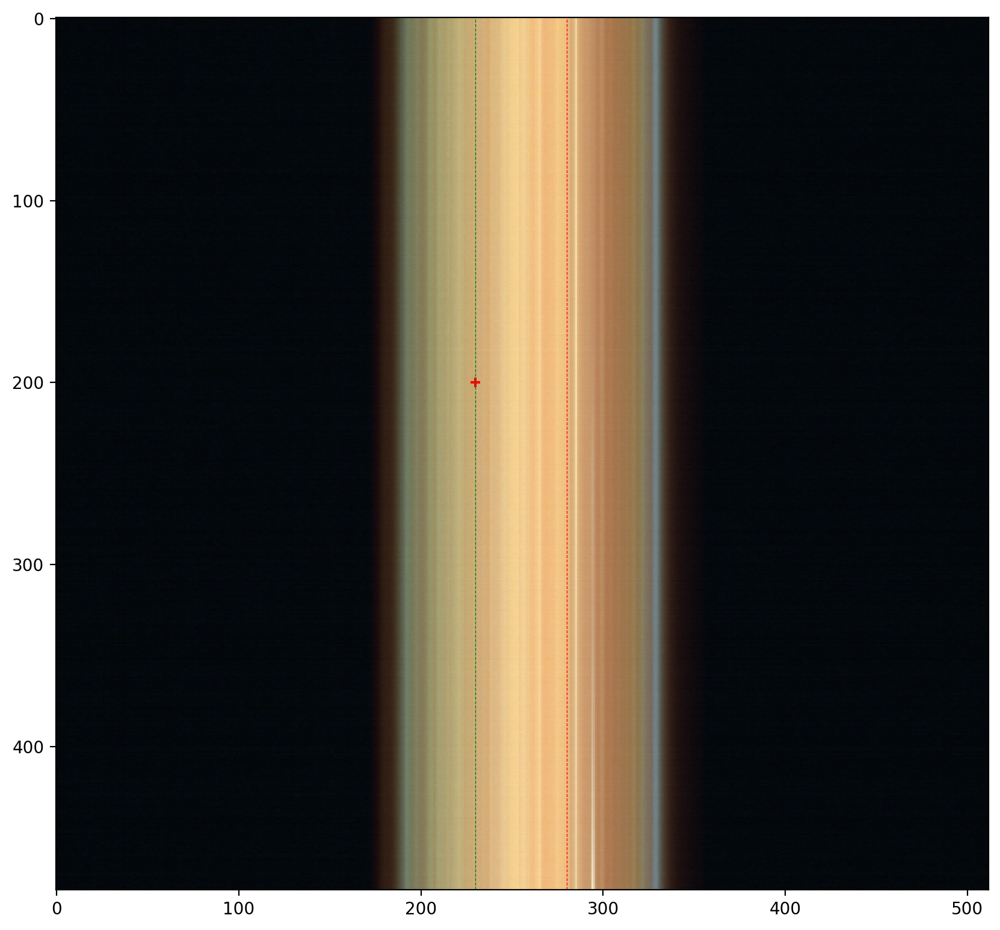

In [ ]:
abl, nabl = coords[sample]
cube.view()
cube.vline(abl, color='red', ls='--', lw='0.5')
cube.vline(nabl, color='green', ls='--', lw='0.5')
cube.point(nabl, 200)

In [ ]:
# Analysis-specific function
def get_spectra(cube, x, band_start=None, band_end=None):

  data = cube.processed[:, x, band_start:band_end]
  data = pd.DataFrame(data, columns=cube.wvls[band_start:band_end])

  metadata = pd.DataFrame({
      'Frame': range(len(data)),
      'Time_s': [round(frame_to_second(frame, frame_rate)) for frame in range(len(data))],
      'Phase': None
  }, index=range(len(data)))

  cutoff_scan_m = 0.5
  cutoff_ablation_m = cutoff_scan_m + 1

  metadata.loc[metadata['Time_s'] < cutoff_scan_m * 60, 'Phase'] = 'prescan'
  metadata.loc[(metadata['Time_s'] >= cutoff_scan_m * 60) & (metadata['Time_s'] < cutoff_ablation_m * 60), 'Phase'] = 'ablation'
  metadata.loc[(metadata['Time_s'] >= cutoff_ablation_m * 60), 'Phase'] = 'monitoring'

  if data.index.equals(metadata.index):
    data = pd.concat([metadata, data], axis=1)

  return data

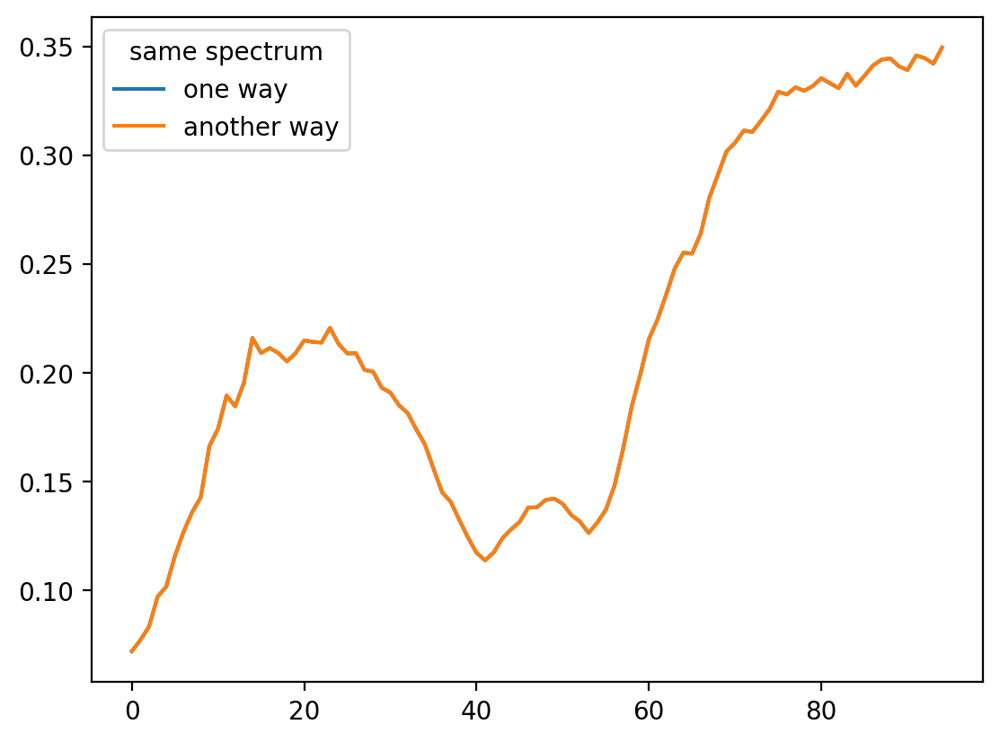

In [ ]:
spectrum = cube.processed[cube.point_y, cube.point_x, 15:110]
plt.plot(spectrum, label='one way')

df = get_spectra(cube, cube.point_x, band_start=15, band_end=110)
plt.plot(df.iloc[cube.point_y, 3:].values, label='another way')

plt.legend(title='same spectrum')

In [ ]:
framestep = 1
duration_m = 1

band_start = 15
band_end = 110

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

df1 = get_spectra(cube, abl, band_start, band_end)
data1 = df1.iloc[:, 3:].values
wvls1 = df1.iloc[:, 3:].columns.astype(float)
metadata1 = df1.iloc[:, :3].values

df2 = get_spectra(cube, nabl, band_start, band_end)
data2 = df2.iloc[:, 3:].values
wvls2 = df2.iloc[:, 3:].columns.astype(float)
metadata2 = df2.iloc[:, :3].values

if len(data1) == len(data2):
    frames = range(0, len(data1), framestep)
else:
    raise ValueError('Data lengths do not match.')

fps = len(frames) / (duration_m * 60)

In [ ]:
i = 0
m, s = frame_to_time(i, frame_rate)

# ----

titlesize=11
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.suptitle(f'{sample} | {condition[sample]}', y=0.98, fontsize=13)

fig.subplots_adjust(
    left=0.1,
    right=0.9,
    bottom=0.12,
    top=0.85,
    wspace=0.25
)

ax = axes[0]
line1, = ax.plot(wvls1, data1[i], lw=2) # will .set_data
ax.set_xlim(wvls1.min(), wvls1.max())
ax.set_ylim(0, 1)
ax.set_xlabel("Wavelength")
ax.set_ylabel("Rel. Reflectance")
title1 = ax.set_title(f"Ablation Pixel | Time = {m:02d}:{s:02d} | {metadata1[i, 2].capitalize()}", loc='center', ha='center', pad=10, fontsize=titlesize)

ax = axes[1]
line2, = ax.plot(wvls2, data2[i], lw=2) # will .set_data
ax.set_xlim(wvls2.min(), wvls2.max())
ax.set_ylim(0, 1)
ax.set_xlabel("Wavelength")
ax.set_ylabel(None)
ax.set_yticks([])
title2 = ax.set_title(f"Non-ablation Pixel | Time = {m:02d}:{s:02d} | {metadata2[i, 2].capitalize()}", loc='center', ha='center', pad=10, fontsize=titlesize)

def update(i):
  print(f'Updating frame {i}')

  m, s = frame_to_time(i, frame_rate)

  line1.set_data(wvls1, data1[i])
  line2.set_data(wvls2, data2[i])

  title1.set_text(f"Ablation Pixel | Time = {m:02d}:{s:02d} | {metadata1[i, 2].capitalize()}")
  title2.set_text(f"Non-Ablation Pixel | Time = {m:02d}:{s:02d} | {metadata2[i, 2].capitalize()}")

  return line1, line2, title1, title2

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    # frames=range(0, 30),
    interval=100,
    blit=True
)

writer = FFMpegWriter(fps=fps, bitrate=3000)

ani.save(
    analysis / f"Timelapse_{sample}.mp4",
    writer=writer,
    dpi=200
)

plt.close(fig)

Updating frame 0
Updating frame 0
Updating frame 0
Updating frame 0
Updating frame 1
Updating frame 2
Updating frame 3
Updating frame 4
Updating frame 5
Updating frame 6
Updating frame 7
Updating frame 8
Updating frame 9
Updating frame 10
Updating frame 11
Updating frame 12
Updating frame 13
Updating frame 14
Updating frame 15
Updating frame 16
Updating frame 17
Updating frame 18
Updating frame 19
Updating frame 20
Updating frame 21
Updating frame 22
Updating frame 23
Updating frame 24
Updating frame 25
Updating frame 26
Updating frame 27
Updating frame 28
Updating frame 29
Updating frame 30
Updating frame 31
Updating frame 32
Updating frame 33
Updating frame 34
Updating frame 35
Updating frame 36
Updating frame 37
Updating frame 38
Updating frame 39
Updating frame 40
Updating frame 41
Updating frame 42
Updating frame 43
Updating frame 44
Updating frame 45
Updating frame 46
Updating frame 47
Updating frame 48
Updating frame 49
Updating frame 50
Updating frame 51
Updating frame 52
Updat

---

# PREV

In [ ]:
# analysis-level function
def get_spectra(cube, which_data='processed', x, trim_bands=None, n_group=None, long=False):

  data = getattr(cube, which_data)

  spectra = data[:, x, :]
  spectra = pd.DataFrame(spectra, columns=cube.wvls)
  if trim_bands is not None:
    spectra = spectra.iloc[:, trim_bands[0]:trim_bands[1]]

  metadata = pd.DataFrame({
      'Frame': range(len(spectra)),
      'Time_s': [round(frame_to_second(frame, frame_rate)) for frame in range(len(spectra))],
      'Phase': None
  }, index=range(len(spectra)))

  cutoff_scan_m = 1
  cutoff_ablation_m = cutoff_scan_m + 5
  cutoff_monitoring_m = cutoff_ablation_m + 10

  metadata.loc[metadata['Time_s'] < cutoff_scan_m * 60, 'Phase'] = 'prescan'
  metadata.loc[(metadata['Time_s'] >= cutoff_scan_m * 60) & (metadata['Time_s'] < cutoff_ablation_m * 60), 'Phase'] = 'ablation'
  metadata.loc[(metadata['Time_s'] >= cutoff_ablation_m * 60), 'Phase'] = 'monitoring'

  if spectra.index.equals(metadata.index):
    df = pd.concat([metadata, spectra], axis=1)
  else:
    raise ValueError('Indices do not match.')

  if n_group:
    df = df.groupby('Phase').sample(n_group, random_state=42).sort_index()

  if long == True:
    df = df.melt(id_vars=['Frame', 'Time_s', 'Phase'], var_name='Wavelength', value_name='Intensity')

  return df

In [ ]:
!pip install av

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 21.4 MB/s eta 0:00:00


In [ ]:
# analysis-level function
def which_second(frame, frame_rate):
  second = (frame+1) / frame_rate
  return int(np.ceil(second))

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
pca = PCA(n_components=2)

pca.fit(data)


# SAMPLE

In [ ]:
sample = 'Sample4'

In [ ]:
analysis = dataset / 'Analysis_v2'
analysis.mkdir(exist_ok=True)

## HSI

In [ ]:
frame_rate = 3.01;

cube_path = dataset / f'HSI_{sample}'
dark_path = dataset / f'HSI_{sample}_Dark'
white_path = dataset / f'HSI_WhiteReference_LowerIntensity'
scale_path = dataset / f'HSI_{sample}_Scale'

cube = Cube(cube_path)
dark = Cube(dark_path)
white = Cube(white_path)
scale = Cube(scale_path)

cube.color_bands = bin_bands(cube.color_bands, 1, 2)

cube.processed = cube.raw - np.mean(dark.raw, axis=0)
white.processed = white.raw - np.mean(dark.raw, axis=0)
scale.processed = scale.raw - np.mean(dark.raw, axis=0)
cube.reflectance = cube.processed / (np.mean(white.processed, axis=0) + np.finfo(np.float32).eps)

cube.get_rgb(which_data='processed', color_bands=cube.color_bands)

hs_frames = cube.processed.shape[0]
hs_duration = frame_to_second(hs_frames, frame_rate)

del dark
del cube.raw
del cube.processed

/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


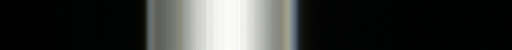

In [ ]:
white_rgb = white.get_rgb(which_data='processed', color_bands=cube.color_bands).rgb
del white
white_rgb

In [ ]:
scale_rgb = scale.get_rgb(which_data='processed', color_bands=cube.color_bands).rgb
del scale
scale_rgb

---

## TI Calibration

In [ ]:
frames = cube.reflectance.shape[0]
vid = ThermalVideo(list((dataset / 'TI').glob(f'*{sample}*Imaging*'))[0])

vid.get_data(frames=frames)

Getting frame 0...
Start frame: 0 | Frames PTSs: [0, 3600, 7200, 10800, 14400, 18000, 21600]
Getting frame 1...
Start frame: 8 | Frames PTSs: [28800, 32400, 36000, 39600, 43200, 46800, 50400]
Getting frame 2...
Start frame: 16 | Frames PTSs: [57600, 61200, 64800, 68400, 72000, 75600, 79200]
Getting frame 3...
Start frame: 23 | Frames PTSs: [82800, 86400, 90000, 93600, 97200, 100800, 104400]
Getting frame 4...
Start frame: 31 | Frames PTSs: [111600, 115200, 118800, 122400, 126000, 129600, 133200]
Getting frame 5...
Start frame: 38 | Frames PTSs: [136800, 140400, 144000, 147600, 151200, 154800, 158400]
Getting frame 6...
Start frame: 46 | Frames PTSs: [165600, 169200, 172800, 176400, 180000, 183600, 187200]
Getting frame 7...
Start frame: 53 | Frames PTSs: [190800, 194400, 198000, 201600, 205200, 208800, 212400]
Getting frame 8...
Start frame: 61 | Frames PTSs: [219600, 223200, 226800, 230400, 234000, 237600, 241200]
Getting frame 9...
Start frame: 68 | Frames PTSs: [244800, 248400, 2520

KeyboardInterrupt: 

In [ ]:
# Temperature reference ROIs (x, y)
width = 10
temp_rois = {
    1: (725, 5),
    2: (566, 2),
    3: (392, 2),
    4: (220, 2),
    5: (56, 2),
}

In [ ]:
cal_data = pd.read_csv(dataset / f'TI_Calibration.csv').set_index('Position')
cal_data['Temp_C'] = cal_data[['Temp_C_ExprStart', 'Temp_C_ExprEnd']].mean(axis=1)
cal_data

## TI vs. Probe Comparison

In [ ]:
def plot_probe_pixel(sample, x, y, w=10, h=10):

  # Probe data
  filepath = dataset / f'0730_temperature_charts.csv'
  probe_data = pd.read_csv(filepath).dropna(how='all', axis=1)
  probe_data.columns = ['Time_s_Sample1', 'Temp_C_Sample1', 'Time_s_Sample2', 'Temp_C_Sample2', 'Time_s_Sample3', 'Temp_C_Sample3', 'Time_s_Sample4', 'Temp_C_Sample4']
  probe_data.set_index('Time_s_Sample2', inplace=True)
  probe_data = probe_data[[col for col in probe_data.columns if 'Temp' in col]].drop('time [s]')
  probe_data.columns = ['Probe_Sample1', 'Probe_Sample2', 'Probe_Sample3', 'Probe_Sample4']
  probe_data.index.name = 'Time_s'
  probe_data.index = probe_data.index.astype(float)
  probe_data = probe_data.astype(float)

  # TI Data
  temps = [64.0, 58.5, 52.0, 46.0, 42.0]
  coords = [(725, 5, w, h), (566, 2, w, h), (392, 2, w, h), (220, 2, w, h), (56, 2, w, h)]
  cal = TMCal(vid.data, coords, temps)
  pixel = cal.get_temp((x, y, w, h))

  pixel = pd.DataFrame({
      'Frame': range(0, len(pixel)),
      f'TI_{sample}': pixel,
  }).astype(float)

  pixel['Time_s'] = pixel['Frame'].apply(lambda x: frame_to_second(x, frame_rate))
  pixel = pixel.set_index('Time_s')

  pixel = pixel.drop('Frame', axis=1)

  temp_data = pd.concat([probe_data[f'Probe_{sample}'], pixel[f'TI_{sample}']], axis=1).sort_index()

  return sns.lineplot(temp_data, dashes=False)

In [ ]:
probe_rois = {
    'Sample1': (489, 489, 5),
    'Sample2': (488, 490, 5),
    'Sample3': (490, 490, 5),
    'Sample4': (489, 490, 5),
    }

Saving TI_Probe_Comparison_Sample2_ROI_Frame1500...


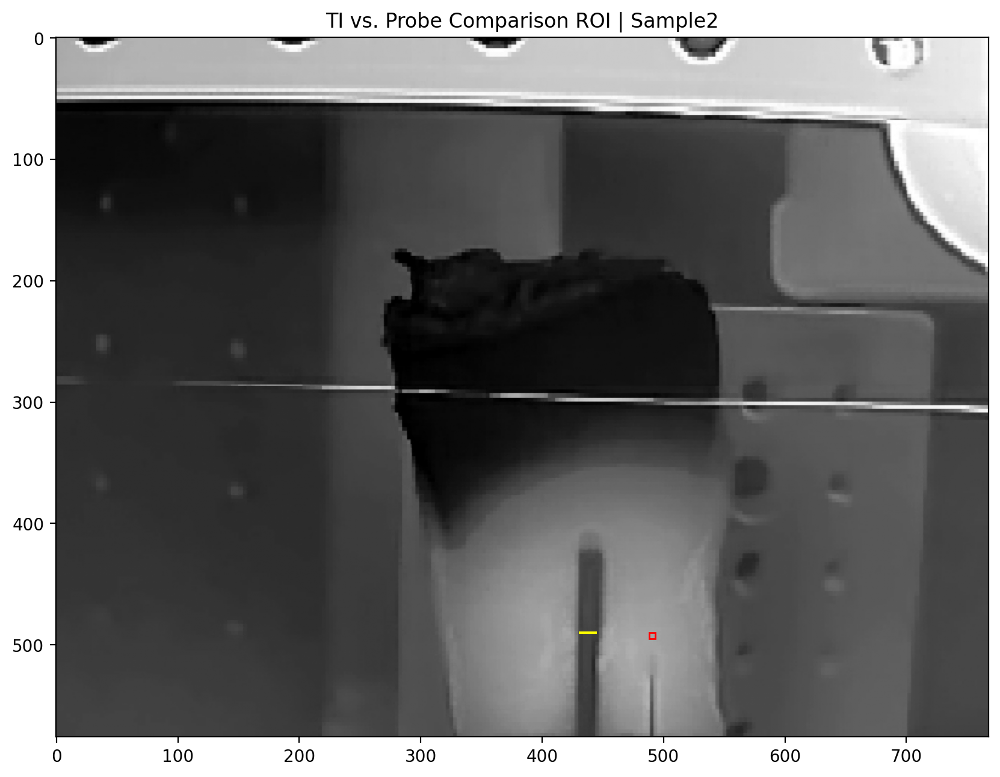

In [ ]:
from matplotlib.patches import Rectangle

frame = 0
frame = 500
frame = 1500

plt.figure(figsize=(10, 10))
plt.imshow(vid.data[:, :, frame], cmap='grey')

x1, y1, w = probe_rois[sample]
rect = Rectangle((x1, y1), w, w, edgecolor='red', facecolor='none')
plt.gca().add_patch(rect)

x2, y2 = 420, y1 # Sample1
x2, y2 = 430, y1 # Sample2
# x2, y2 = 431, y1 # Sample3
plt.gca().hlines(y2, xmin=x2, xmax=x2+15, color='yellow')

plt.title(f'TI vs. Probe Comparison ROI | {sample}')

filepath = analysis / f'TI_Probe_Comparison_{sample}_ROI_Frame{frame}.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
w = 10; h = 10
ref_coords = [(725, 5, w, h), (566, 2, w, h), (392, 2, w, h), (220, 2, w, h), (56, 2, w, h)]
temps = cal_data['Temp_C'].to_numpy()
cal = TMCal(vid.data, ref_coords, temps)

In [ ]:
df = pd.DataFrame(index = frame_to_second(np.array(range(0, vid.data.shape[2])), frame_rate))
for i in temp_rois:
  x = temp_rois[i][0]
  y = temp_rois[i][1]
  temp = cal.get_temp((x, y, w, h))
  df[f'RefPos_{i} | {int(temps[i-1])}°C'] = temp
  df.index.name = 'Second'

Saving TempEstimation_RefPositions_Sample2_new...


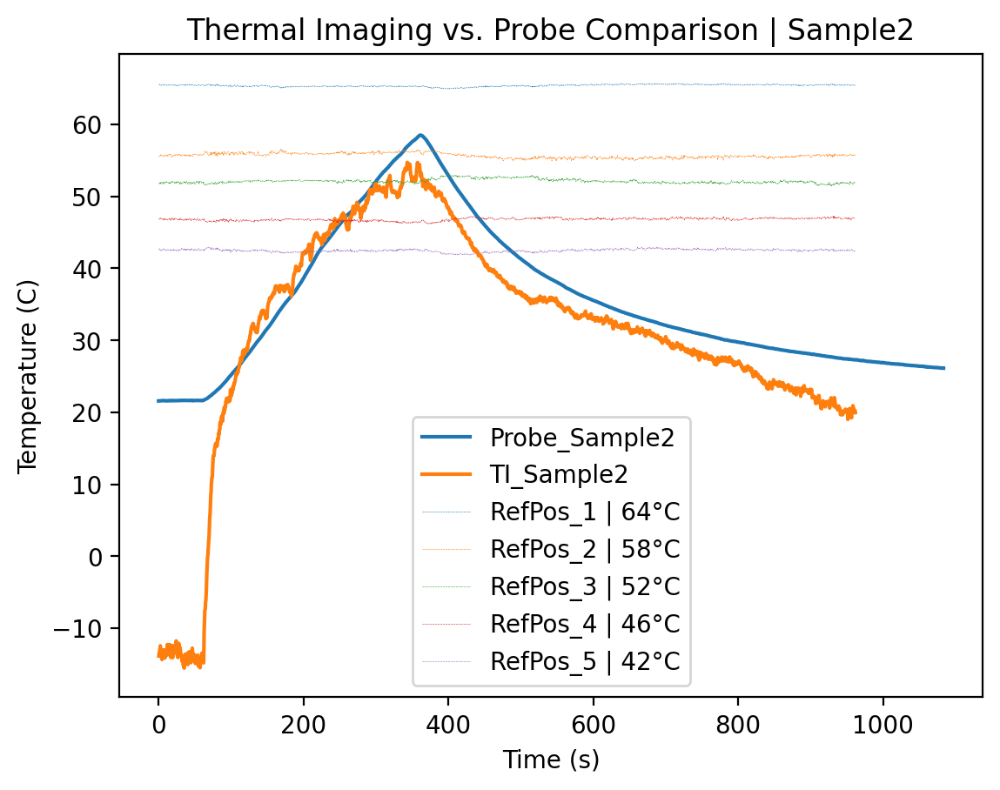

In [ ]:
plot_probe_pixel(sample, x1, y1, w, h)
plt.xlabel('Time (s)')
plt.ylabel('Temperature (C)')
plt.title(f'Thermal Imaging vs. Probe Comparison | {sample}')

ax = plt.gca()
sns.lineplot(df, lw=0.2, ls='--', dashes=False, ax=ax)

filepath = analysis / f'TempEstimation_RefPositions_{sample}_new.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

Saving TI_Calibration_Sample2...


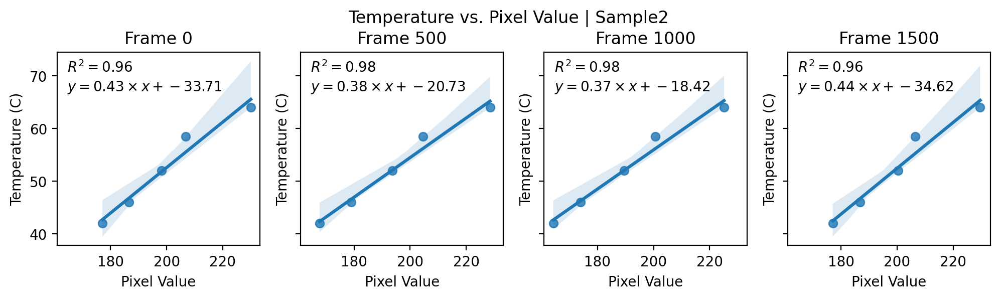

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(12, 2.5), sharex=True, sharey=True)
axes = axes.flatten()

for i, f in enumerate([0, 500, 1000, 1500]):
  ax = axes[i]
  x = cal.ref_pixels[:, f]
  y = cal.temps
  r_square = cal.r_squares[f]
  formula = cal.formulas[f]

  sns.regplot(x=x, y=y, ax=ax)
  ax.set_title(f'Frame {f}')
  ax.set_xlabel('Pixel Value')
  ax.set_ylabel('Temperature (C)')
  ax.text(0.05, 0.9, f'$R^2 = {r_square:.2f}$', transform=ax.transAxes)
  ax.text(0.05, 0.8, formula, transform=ax.transAxes)
plt.suptitle(f'Temperature vs. Pixel Value | {sample}', y=1.05)

filepath = analysis / f'TI_Calibration_{sample}.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

Saving Example_Calibration_ROIs_Sample2...


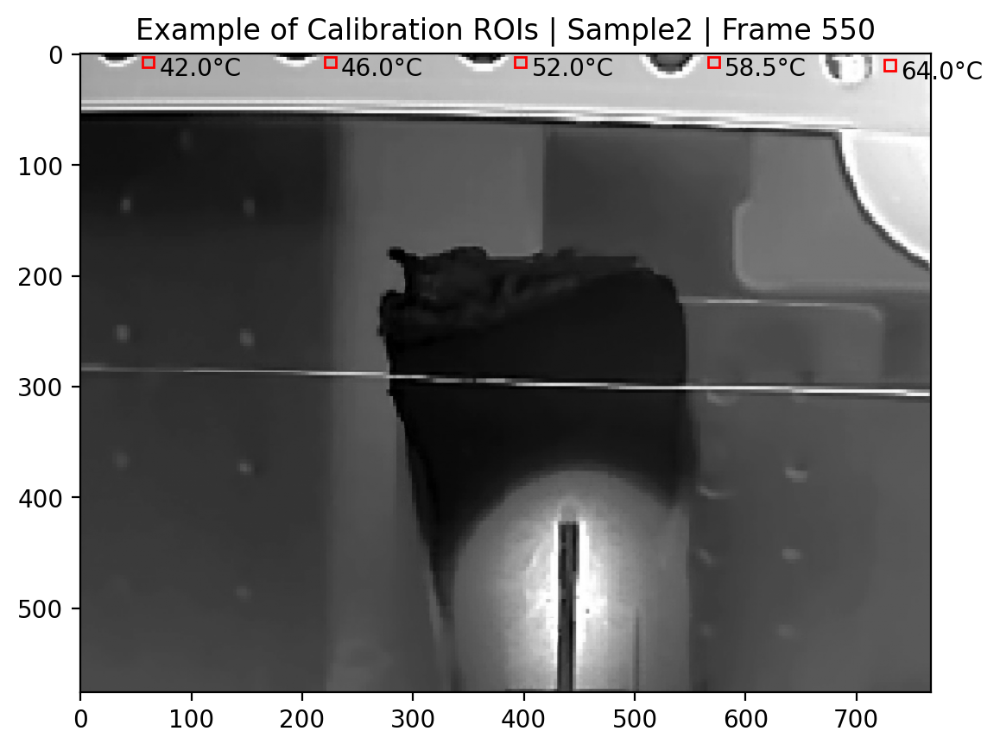

In [ ]:
frame = 550
plt.imshow(cal.data[:, :, frame], cmap='grey')

for coord, temp in zip(cal.coords, cal.temps):
  x, y, w, h = coord
  rect = Rectangle((x, y), w, h, edgecolor='red', facecolor='none')
  plt.gca().add_patch(rect)
  plt.text(x+w+w/2, y, f'{temp:.1f}°C', ha='left', va='top', color='black')

plt.title(f'Example of Calibration ROIs | {sample} | Frame {frame}')
filepath = analysis / f'Example_Calibration_ROIs_{sample}.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

---

## Pixel-Pixel Mapping

In [ ]:
smpl = 'Sample2'

In [ ]:
abl_coords = {
    'Sample1-l': (200, 170),
    'Sample1-r': (217, 265),
    'Sample3-r': (230, 275),
    'Sample3-m': (201, 260),
    'Sample2': (225, 262),
    'Sample4-r': (220, 265),
}

antenna_coords_hs = {
    'Sample1': (203, 212),
    'Sample3': (209, 217),
    'Sample2': (210, 218),
    'Sample4': (206, 214),
}

Saving PP_Mapping_Sample2_HS...


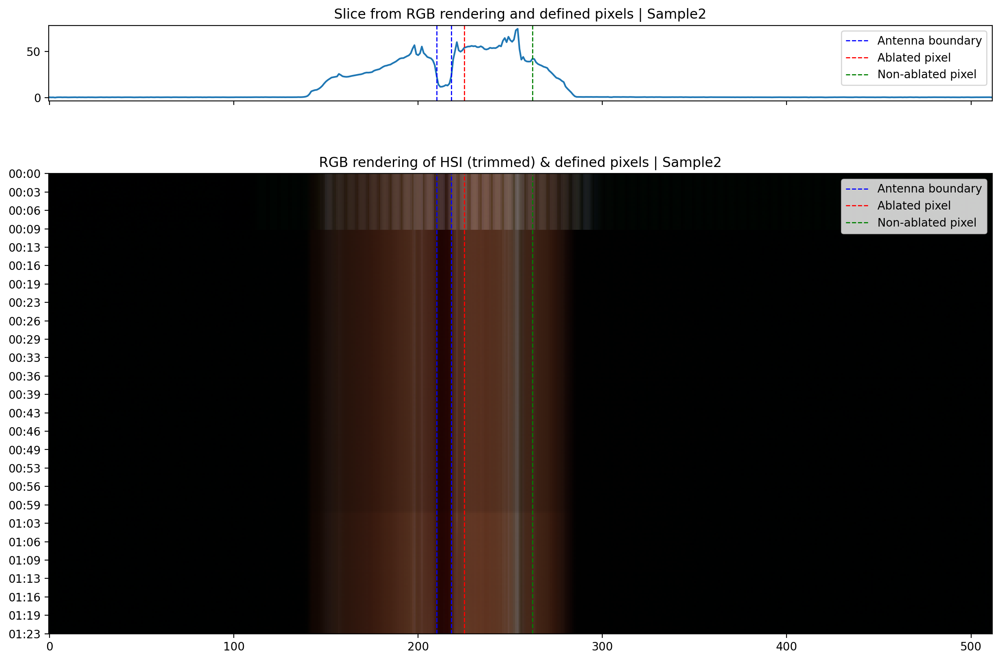

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True, height_ratios=[2, 13])

# A slice from RGB to show the signal and detect antenna boundaries
ax = axes[0]
ax.set_title(f'Slice from RGB rendering and defined pixels | {smpl}')
aslice = np.array(cube.rgb)[50:60, :, :].mean(axis=(0, 2))
sns.lineplot(aslice, ax=ax)

# RGB rendering of HSI
ax = axes[1]
ax.set_title(f'RGB rendering of HSI (trimmed) & defined pixels | {smpl}')
ax.imshow(cube.rgb)
ax.imshow(scale_rgb, alpha=0.2)
ax.set_ylim(0, 250)

myrange = range(0, 251, 10)
time = [f'{frame_to_time(i, frame_rate)[0]:02d}:{frame_to_time(i, frame_rate)[1]:02d}' for i in myrange]
ax.set_yticks(myrange)
ax.set_yticklabels(time)
ax.invert_yaxis()

# Calculating antenna width as a scale reference
left, right = antenna_coords_hs[sample]
pixels_hs = right-left

abl_hs, nabl_hs = abl_coords[smpl]
dist_abl_hs = abl_hs - right
dist_nabl_hs = nabl_hs - right

# Marking the pixels
for ax in axes:
  ax.axvline(left, color='blue', ls='--', lw=1, label='Antenna boundary')
  ax.axvline(right, color='blue', ls='--', lw=1)
  ax.axvline(abl_hs, color='red', ls='--', lw=1, label='Ablated pixel')
  ax.axvline(nabl_hs, color='green', ls='--', lw=1, label='Non-ablated pixel')

axes[0].legend()
axes[1].legend()

filepath = analysis / f'PP_Mapping_{smpl}_HS.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
antenna_coords_th = {
    'Sample1': (421, 434),
    'Sample3': (430, 446),
    'Sample2': (430, 444),
    'Sample4': (427, 441),
}

scanlines = {
    'Sample1': 459,
    'Sample3': 488,
    'Sample2': 486,
    'Sample4': 496,
}

Start frame: 0 | Frames PTSs: [0]
Saving PP_Mapping_Sample2_TI_Alignment_0...


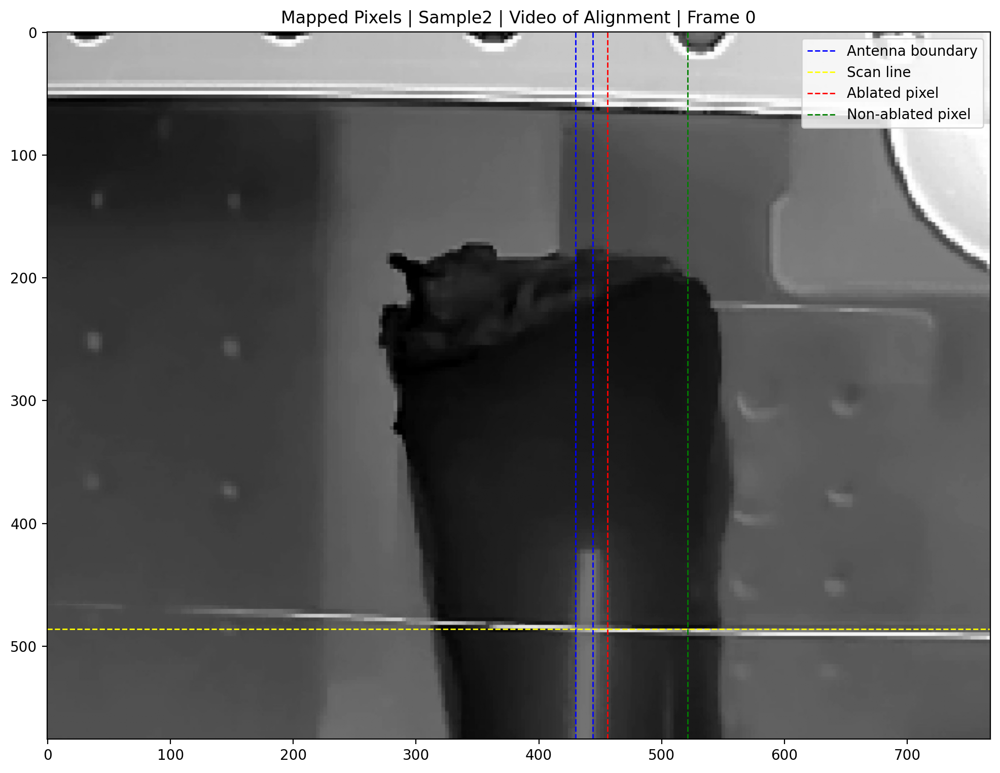

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))

which_vid = 'Imaging'
which_vid = 'Alignment'
vid_ = ThermalVideo(list((dataset / 'TI').glob(f'*{sample}*{which_vid}*'))[0])

if which_vid == 'Imaging':
  frame = 1500
  aframe = vid_.get_corresponding_frame(frame, cube.reflectance.shape[0])
elif which_vid == 'Alignment':
  frame = 0
  aframe = vid_.get_corresponding_frame(frame, vid_.frames)
ax.imshow(aframe, cmap='grey')

left, right = antenna_coords_th[sample]
pixels_th = right-left

ppp = pixels_th / pixels_hs
dist_abl_th = dist_abl_hs * ppp
dist_nabl_th = dist_nabl_hs * ppp

abl_th = int(right + dist_abl_th)
nabl_th = int(right + dist_nabl_th)

scanline = scanlines[sample]

ax.axvline(left, color='blue', ls='--', lw=1, label='Antenna boundary')
ax.axvline(right, color='blue', ls='--', lw=1)

ax.axhline(scanline, color='yellow', ls='--', lw=1, label='Scan line')

ax.axvline(abl_th, color='red', ls='--', lw=1, label='Ablated pixel')
ax.axvline(nabl_th, color='green', ls='--', lw=1, label='Non-ablated pixel')

ax.legend()
ax.set_title(f'Mapped Pixels | {smpl} | Video of {which_vid} | Frame {frame}')

filepath = analysis / f'PP_Mapping_{smpl}_TI_{which_vid}_{frame}.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

## Animation

In [ ]:
cube.reflectance.shape[1] == np.array(scale_rgb).shape[1]

True

In [ ]:
# Calibrate
w = 10
temp_coords = [(v[0], v[1], w, w) for k, v in temp_rois.items()]
cal = TMCal(vid.data, temp_coords, temps)

# Get pixel temperature data
scanline = scanlines[sample]
temp_abl = cal.get_temp((abl_th, scanline) + (1, 1))
temp_nabl = cal.get_temp((nabl_th, scanline) + (1, 1))

# Smooth temp data
from scipy.ndimage import gaussian_filter1d
temp_abl = gaussian_filter1d(temp_abl, sigma=10)
temp_nabl = gaussian_filter1d(temp_nabl, sigma=10)

time = frame_to_second(np.array(range(0, len(temp_abl))), frame_rate) / 60

In [ ]:
# sns.lineplot(x=time, y=temp_abl, label=f'Ablation pixel', color='red')
# sns.lineplot(x=time, y=temp_nabl, label=f'Non-ablation pixel', color='green')

# plt.xlabel(f'Time (min)')
# plt.ylabel(f'Temperature (°C)')
# plt.title(f'Temperature vs. Time (ThermalMaster) | {smpl}')

# filepath = analysis / f'Temp_vs_Time_{smpl}.png'
# print(f'Saving {filepath.stem}...')
# plt.savefig(filepath, dpi=200, bbox_inches='tight')
# plt.show()

In [ ]:
framestep = 1
duration_m = 3

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

df1 = get_spectra(cube, 'reflectance', abl_hs, trim_bands=(10, 120))
data1 = df1.iloc[:, 3:].values
wvls1 = df1.iloc[:, 3:].columns.astype(float)
metadata1 = df1.iloc[:, :3].values

df2 = get_spectra(cube, 'reflectance', nabl_hs, trim_bands=(10, 120))
data2 = df2.iloc[:, 3:].values
wvls2 = df2.iloc[:, 3:].columns.astype(float)
metadata2 = df2.iloc[:, :3].values

if len(data1) == len(data2):
    frames = range(0, len(data1), framestep)
else:
    raise ValueError('Data lengths do not match.')

fps = len(frames) / (duration_m * 60)

In [ ]:
# v1
i = 0
m, s = frame_to_time(i, frame_rate)

# ----

titlesize=11
fig, axes = plt.subplot_mosaic([
      ['A', 'B', 'C', 'D'],
      ['E', 'E', 'F', 'F']],
      figsize=(10, 10),
      gridspec_kw={'width_ratios': [15, 1, 15, 1]})

fig.subplots_adjust(
    left=0.06,
    right=0.98,
    bottom=0.05,
    top=0.95,
    wspace=0.25
)

ax = axes['A']
line1, = ax.plot(wvls1, data1[i], lw=2) # will .set_data
ax.set_xlim(wvls1.min(), wvls1.max())
ax.set_ylim(0, 2.1)
ax.set_xlabel("Wavelength")
ax.set_ylabel("Rel. Reflectance")
title1 = ax.set_title(f"Ablation Pixel | Time = {m:02d}:{s:02d} | {metadata1[i, 2].capitalize()}", loc='center', ha='center', pad=10, fontsize=titlesize)

ax = axes['B']
bar1, = ax.bar([0], [temp_abl[i]], width=0.8, color='r') # will .set_height
ax.set_xlim(-0.5, 0.5)
ax.set_ylim(0, 100)
ax.set_xticks([])
ax.set_ylabel(None)
ax.set_title(f'Temp.', pad=10, fontsize=titlesize)

bar1_text = ax.text(0, temp_abl[i] + 3, f'{temp_abl[i]:.1f} °C', ha='center', va='bottom')

ax = axes['C']
line2, = ax.plot(wvls2, data2[i], lw=2) # will .set_data
ax.set_xlim(wvls2.min(), wvls2.max())
ax.set_ylim(0, 2.1)
ax.set_xlabel("Wavelength")
ax.set_ylabel(None)
ax.set_yticks([])
title2 = ax.set_title(f"Non-ablation Pixel | Time = {m:02d}:{s:02d} | {metadata2[i, 2].capitalize()}", loc='center', ha='center', pad=10, fontsize=titlesize)

ax = axes['D']
bar2, = ax.bar([0], [temp_nabl[i]], width=0.8, color='g')
ax.set_xlim(-0.5, 0.5)
ax.set_ylim(0, 100)
ax.set_xticks([])
ax.set_ylabel(None)
ax.set_title(f'Temp.', pad=10, fontsize=titlesize)

bar2_text = ax.text(0, temp_nabl[i] + 3, f'{temp_nabl[i]:.1f} °C', ha='center', va='bottom')

ax = axes['E']
img = ax.imshow(cal.data[:, :, i], cmap='grey')
# title3 = ax.set_title(f"Time = {m:02d}:{s:02d} | {metadata2[i, 2].capitalize()}", loc='center', ha='center', pad=10, fontsize=titlesize)
ax.scatter(abl_th, scanline, color='r', marker='+', label='Ablation Pixel')
ax.scatter(nabl_th, scanline, color='g', marker='+', label='Non-Ablation Pixel')
ax.legend(loc='upper left', bbox_to_anchor=(0.05, 0.85), fontsize=titlesize)

ax = axes['F']
ax.plot(time, temp_abl, label=f'Ablation pixel', color='red')
ax.plot(time, temp_nabl, label=f'Non-ablation pixel', color='green')
ax.set_xlabel(f'Time (min)')
ax.set_ylabel(f'Temperature (°C)')
ax.legend()
timevline = ax.axvline(time[i], color='black', ls='--', lw=1)

def update(i):
  print(f'Updating frame {i}')

  m, s = frame_to_time(i, frame_rate)

  line1.set_data(wvls1, data1[i])
  line2.set_data(wvls2, data2[i])

  bar1.set_height(temp_abl[i])
  bar2.set_height(temp_nabl[i])

  bar1_text.set_y(temp_abl[i] + 3)
  bar1_text.set_text(f'{temp_abl[i]:.1f} °C')

  bar2_text.set_y(temp_nabl[i] + 3)
  bar2_text.set_text(f'{temp_nabl[i]:.1f} °C')

  title1.set_text(f"Ablation Pixel | Time = {m:02d}:{s:02d} | {metadata1[i, 2].capitalize()}")
  title2.set_text(f"Non-Ablation Pixel | Time = {m:02d}:{s:02d} | {metadata2[i, 2].capitalize()}")

  img.set_data(cal.data[:, :, i])

  timevline.set_xdata([time[i], time[i]])

  return line1, line2, bar1, bar2, bar1_text, bar2_text, title1, title2, img, timevline

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    # frames=range(0, 20),
    interval=100,
    blit=True
)

writer = FFMpegWriter(fps=fps, bitrate=3000)

ani.save(
    analysis / f"Progression_{smpl}_1.mp4",
    writer=writer,
    dpi=200
)

plt.close(fig)

Updating frame 0
Updating frame 0
Updating frame 0
Updating frame 0
Updating frame 1
Updating frame 2
Updating frame 3
Updating frame 4
Updating frame 5
Updating frame 6
Updating frame 7
Updating frame 8
Updating frame 9
Updating frame 10
Updating frame 11
Updating frame 12
Updating frame 13
Updating frame 14
Updating frame 15
Updating frame 16
Updating frame 17
Updating frame 18
Updating frame 19
Updating frame 20
Updating frame 21
Updating frame 22
Updating frame 23
Updating frame 24
Updating frame 25
Updating frame 26
Updating frame 27
Updating frame 28
Updating frame 29
Updating frame 30
Updating frame 31
Updating frame 32
Updating frame 33
Updating frame 34
Updating frame 35
Updating frame 36
Updating frame 37
Updating frame 38
Updating frame 39
Updating frame 40
Updating frame 41
Updating frame 42
Updating frame 43
Updating frame 44
Updating frame 45
Updating frame 46
Updating frame 47
Updating frame 48
Updating frame 49
Updating frame 50
Updating frame 51
Updating frame 52
Updat

## Thermal Probe Displacement

In [ ]:
folder = analysis / f'Probe_Displacement'
folder.mkdir(exist_ok=True)

In [ ]:
frames = cube.reflectance.shape[0]

In [ ]:
mydict = {
    'Sample1': {
        'antenna': 212,
        'probe_start': 247,
        'probe_end': 247,
        'tissue_start': 146,
        'tissue_end': 287,
        'units': 23, # 1/16 inch
    },
    'Sample2': {
        'antenna': 218,
        'probe_start': 253,
        'probe_end': 247,
        'tissue_start': 148,
        'tissue_end': 285,
        'units': 22.2, # 1/16 inch
    },
    'Sample3': {
        'antenna': 216,
        'probe_start': 254,
        'probe_end': 246,
        'tissue_start': 146,
        'tissue_end': 307,
        'units': 26, # 1/16 inch
    },
    'Sample4': {
        'antenna': 214,
        'probe_start': 254,
        'probe_end': 246,
        'tissue_start': 146,
        'tissue_end': 28,
        'units': 23, # 1/16 inch
    },
}

Saving Sample4_HSI...





In [ ]:
antenna = mydict[sample]['antenna']
probe_start = mydict[sample]['probe_start']
probe_end = mydict[sample]['probe_end']

tissue_start = mydict[sample]['tissue_start']
tissue_end = mydict[sample]['tissue_end']

units = mydict[sample]['units']

# ---
units_mm = units / 16 * 25.4
pixels = tissue_end - tissue_start
pixel_size_mm = units_mm / pixels
tissue_thickness = (tissue_end - antenna) * pixel_size_mm

fig, axes = plt.subplots(3, 1, figsize=(12, 72), sharex=True, height_ratios=[1, 1, 50])
fig.subplots_adjust(hspace=0.02)

arr = np.array(cube.rgb)

ax = axes[0]
y1 = 20
aslice = arr[y1:y1+10, :, :].mean(axis=(0, 2))
sns.lineplot(aslice, ax=ax, label=f'y={y1}')
ax.set_title(f'Slice from RGB rendering')
ax.axvline(antenna, color='b', ls='--', lw=0.5, label='antenna edge')
ax.axvline(probe_start, color='g', ls='--', lw=0.5, label='probe at start')
ax.axvline(tissue_start, color='y', ls='--', lw=0.5, label='tissue start')
ax.axvline(tissue_end, color='y', ls='--', lw=0.5, label='tissue end')
ax.legend()

ax = axes[1]
y2 = frames - y1
aslice = arr[y2-10:y2, :, :].mean(axis=(0, 2))
sns.lineplot(aslice, ax=ax, label=f'y={y2}')
ax.set_title(f'Slice from RGB rendering')
ax.axvline(antenna, color='b', ls='--', lw=0.5, label='antenna edge')
ax.axvline(probe_end, color='r', ls='--', lw=0.5, label='probe at end')
ax.axvline(tissue_start, color='y', ls='--', lw=0.5, label='tissue start')
ax.axvline(tissue_end, color='y', ls='--', lw=0.5, label='tissue end')
ax.legend()

ax = axes[2]
ax.imshow(scale_rgb, alpha=1, zorder=10)
ax.imshow(cube.rgb)

ax.axvline(antenna, color='b', ls='--', lw=0.5, label='antenna edge')
ax.axvline(probe_start, color='g', ls='--', lw=0.5, label='probe at start')
ax.axvline(probe_end, color='r', ls='--', lw=0.5, label='probe at end')
ax.axvline(tissue_start, color='y', ls='--', lw=0.5, label='tissue start')
ax.axvline(tissue_end, color='y', ls='--', lw=0.5, label='tissue end')
axes[2].set_title(f'RGB rendering of HSI | Probe displaced by {probe_end - probe_start} pixels | Antenna to tissue edge = {tissue_thickness:.2f} mm')
ax.legend()

filepath = folder / f'{sample}_HSI.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

In [ ]:
vid = ThermalVideo(list((dataset / 'TI').glob(f'*{sample}*Imaging*'))[0])

Start frame: 151 | Frames PTSs: [543600, 547200, 550800, 554400, 558000, 561600, 565200]
Start frame: 21645 | Frames PTSs: [77922000, 77925600, 77929200, 77932800, 77936400, 77940000, 77943600]
Saving Sample4_TI...


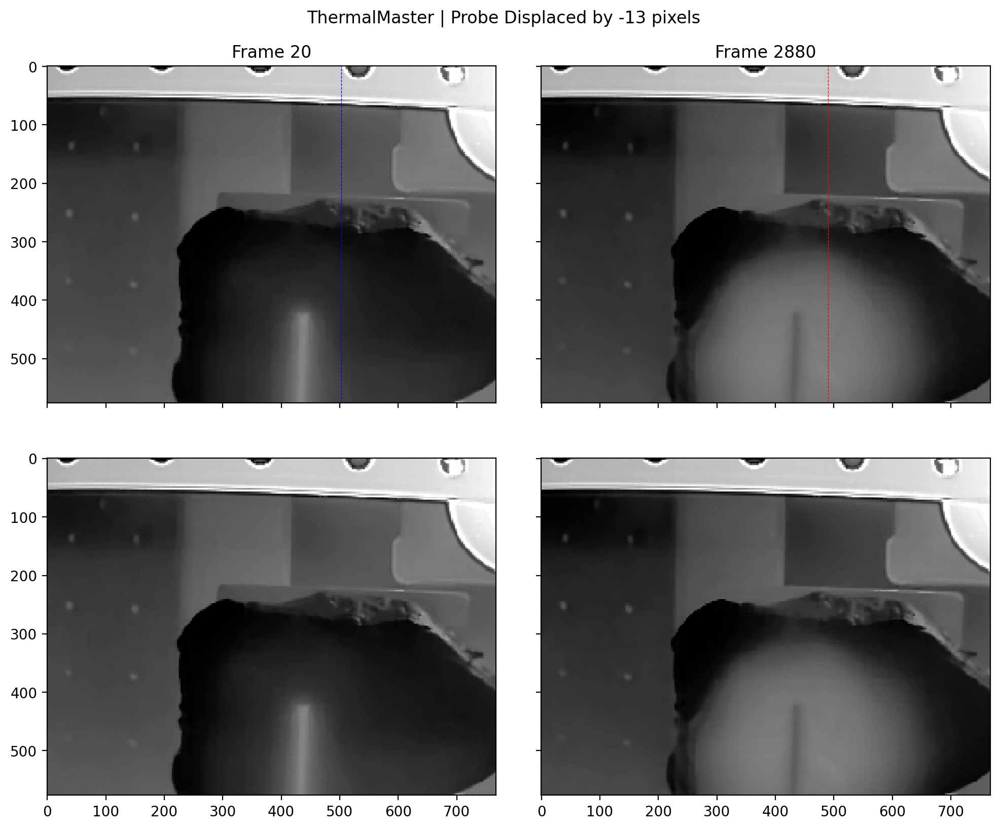

In [ ]:
probe_start = 503
probe_end = 490

fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
axes = axes.flatten()

fig.subplots_adjust(wspace=0.1, hspace=0.01)

ax = axes[0]
f1 = vid.get_corresponding_frame(y1, frames)
ax.imshow(f1, cmap='grey')
ax.axvline(probe_start, color='b', ls='--', lw=0.5)
ax.set_title(f'Frame {y1}')

ax = axes[1]
f2 = vid.get_corresponding_frame(y2, frames)
ax.imshow(f2, cmap='grey')
ax.axvline(probe_end, color='r', ls='--', lw=0.5)
ax.set_title(f'Frame {y2}')

ax = axes[2]
ax.imshow(f1, cmap='grey')

ax = axes[3]
ax.imshow(f2, cmap='grey')

fig.suptitle(f'ThermalMaster | Probe Displaced by {probe_end - probe_start} pixels', y=0.91)

filepath = folder / f'{sample}_TI.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

---

In [ ]:
os.listdir(folder)

['Sample1_HSI.png',
 'Sample1_TI.png',
 'Sample2_HSI.png',
 'Sample2_TI.png',
 'Sample3_HSI.png',
 'Sample3_TI.png',
 'Probe_Discplacement.gsheet',
 'Probe_Discplacement.csv']

In [ ]:
file = folder / 'Probe_Discplacement.csv'
df = pd.read_csv(file)
df['Probe_Displacement_px'] = abs(df['Probe_Displacement_px'])
df

,Sample_ID,Tissue_Thickness_mm,Probe_Displacement_px
0,Sample1,19.42,0
1,Sample2,17.24,6
2,Sample3,23.33,8


<Axes: xlabel='Tissue_Thickness_mm', ylabel='Probe_Displacement_px'>

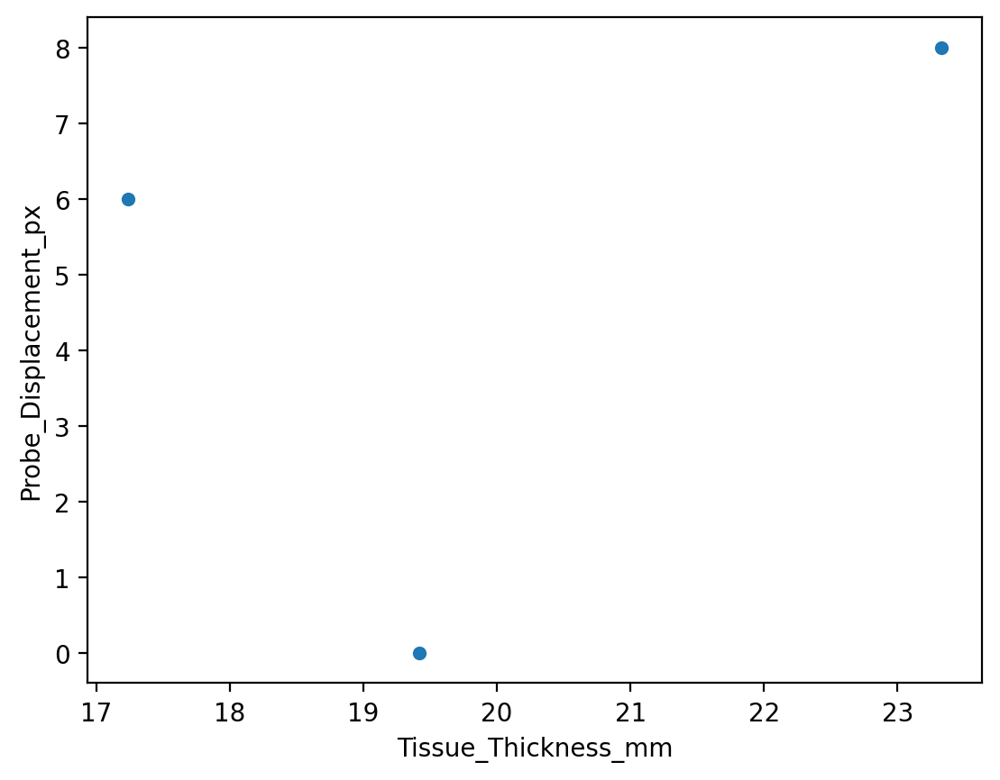

In [ ]:
sns.scatterplot(df, x='Tissue_Thickness_mm', y='Probe_Displacement_px')

# Drafts

# Pixel Size Approach

In [ ]:
antenna_mm = 2.14 # mm




In [ ]:
# Pixel size in HSI

plt.figure(figsize=(15, 100))
plt.imshow(cube.get_rgb('processed').rgb)

x1 = 209
x2 = 217

pixels = x2-x1 # number of pixels covering the antenna diameter
pixel_size_hs = antenna_mm / pixels

plt.axvline(x1, color='r', ls='--', lw=0.5)
plt.axvline(x2, color='r', ls='--', lw=0.5)

probe_dist = 10.3 / pixel_size_hs
probe_pos = x1+pixels/2 + probe_dist
plt.axvline(probe_pos, color='g', ls='--', lw=0.5)

Start frame: 11255 | Frames PTSs: [40518000, 40521600, 40525200, 40528800, 40532400, 40536000, 40539600]


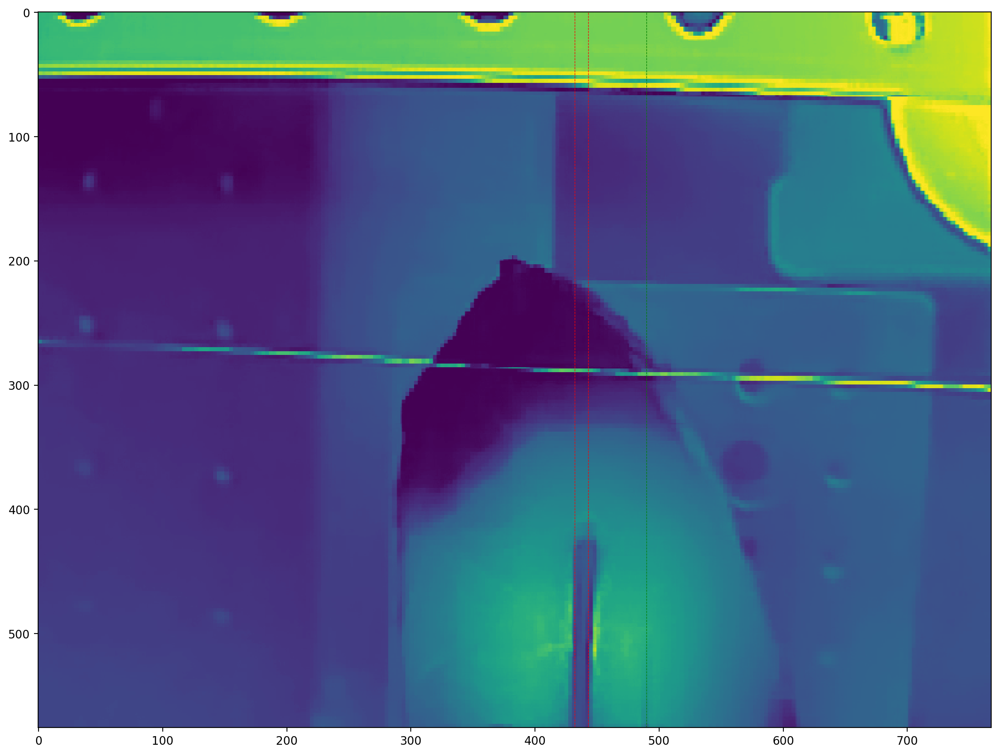

In [ ]:
hs_frame = 1500
plt.figure(figsize=(15, 100))
plt.imshow(get_mean_frame(hs_frame, fpf))

x1 = 432
x2 = 443

pixels = x2-x1 # number of pixels covering the antenna diameter
pixel_size_ti = antenna_mm / pixels

plt.axvline(x1, color='r', ls='--', lw=0.5)
plt.axvline(x2, color='r', ls='--', lw=0.5)

probe_dist = 10.2 / pixel_size_ti
probe_pos = x1+pixels/2 + probe_dist
plt.axvline(probe_pos, color='g', ls='--', lw=0.5)

In [ ]:
pos_path = list((dataset / 'TI').glob(f'*{sample}*Alignment*'))[0]
pos_container = av.open(pos_path)
pos_video = pos_container.streams.video[0]

for i, frame in enumerate(pos_container.decode(pos_video)):
  if i == 50:
    pos_frame = frame.to_ndarray(format="rgb24")
    break

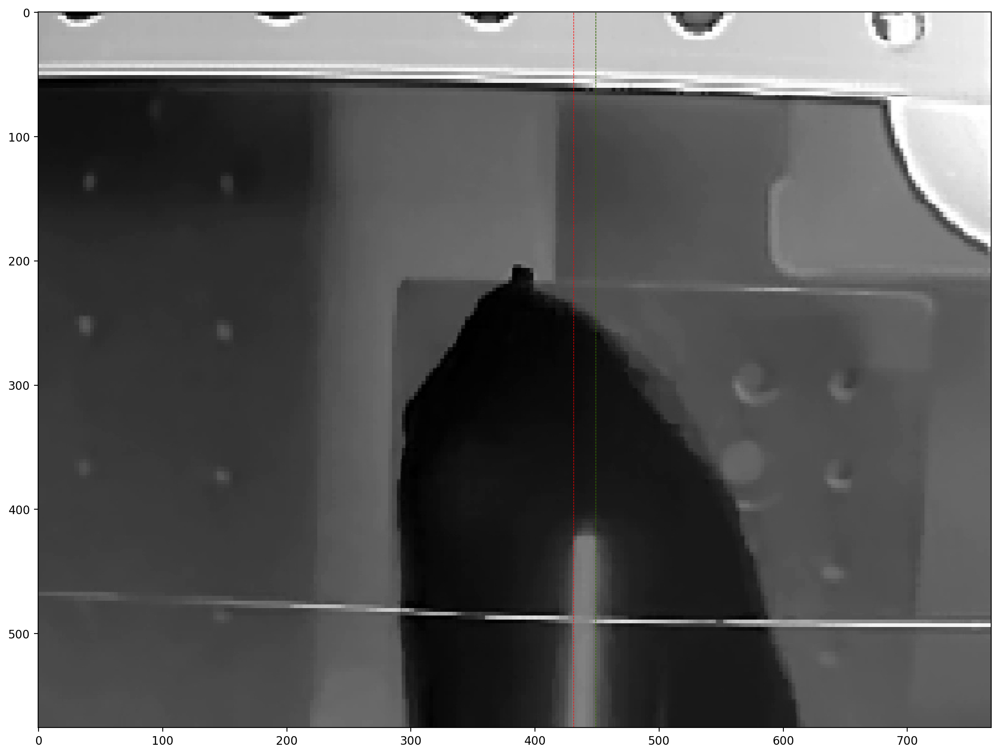

In [ ]:
hs_frame = 1500
plt.figure(figsize=(15, 100))
plt.imshow(pos_frame)

x1 = 431
x2 = 449

pixels = x2-x1 # number of pixels covering the antenna diameter
pixel_size_ti = antenna_mm / pixels

plt.axvline(x1, color='r', ls='--', lw=0.5)
plt.axvline(x2, color='r', ls='--', lw=0.5)

probe_dist = 2.14 / pixel_size_ti
probe_pos = x1 + probe_dist
plt.axvline(probe_pos, color='g', ls='--', lw=0.5)

In [ ]:
target_time = 1  # seconds

# Convert seconds to the stream's timestamp units
target_pts = int(target_time / video.time_base)

# Seek to the nearest preceding keyframe
container.seek(target_pts, stream=video)

# Decode forward until the desired time
for i, frame in enumerate(container.decode(video)):
    print(i, frame.pts, frame.time)
    if frame.time >= target_time+1:
        image = frame.to_ndarray(format="rgb24")
        break

0 0 0.0
1 3600 0.04
2 7200 0.08
3 10800 0.12
4 14400 0.16
5 18000 0.2
6 21600 0.24
7 25200 0.28
8 28800 0.32
9 32400 0.36
10 36000 0.4
11 39600 0.44
12 43200 0.48
13 46800 0.52
14 50400 0.56
15 54000 0.6
16 57600 0.64
17 61200 0.68
18 64800 0.72
19 68400 0.76
20 72000 0.8
21 75600 0.84
22 79200 0.88
23 82800 0.92
24 86400 0.96
25 90000 1.0
26 93600 1.04
27 97200 1.08
28 100800 1.12
29 104400 1.16
30 108000 1.2
31 111600 1.24
32 115200 1.28
33 118800 1.32
34 122400 1.36
35 126000 1.4
36 129600 1.44
37 133200 1.48
38 136800 1.52
39 140400 1.56
40 144000 1.6
41 147600 1.64
42 151200 1.68
43 154800 1.72
44 158400 1.76
45 162000 1.8
46 165600 1.84
47 169200 1.88
48 172800 1.92
49 176400 1.96
50 180000 2.0


In [ ]:
print("FPS:", float(video.average_rate))
print("Width:", video.width)
print("Height:", video.height)
print("Frames:", video.frames)
print("Codec:", video.codec_context.name)
print("Duration (s):", float(video.duration * video.time_base))

FPS: 25.001150536149847
Width: 768
Height: 576
Frames: 21730
Codec: h264
Duration (s): 869.16


In [ ]:
height = video.height
width = video.width
n = video.frames / 23

bytes_needed = n * height * width # uint8 RGB
print(bytes_needed / 1024**3, "GB")

0.38923844047214673 GB


# Static

In [ ]:
# Sample3
coords = {
    'Sample3-1': (230, 275),
    'Sample3-2': (201, 260)
}

Saving RGB_Sample3-1...


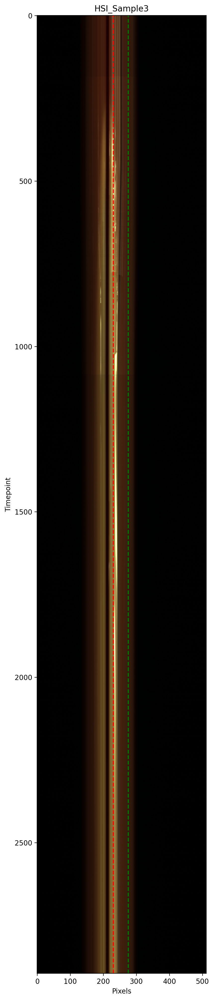

In [ ]:
smpl = 'Sample3-1'

abl, nabl = coords[smpl]

plt.figure(figsize=(15, 25))
plt.imshow(cube.get_rgb(which_data='processed', color_bands=cube.color_bands).rgb)
plt.xlabel(f'Pixels')
plt.ylabel(f'Timepoint')
plt.title(f'{cube.name}')

plt.axvline(nabl, color='g', ls='--')
plt.axvline(abl, color='r', ls='--')

filepath = analysis / f'RGB_{smpl}.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

## Static

In [ ]:
smpl

'Sample3-1'

Saving Spectra_Sample3-1_n10...


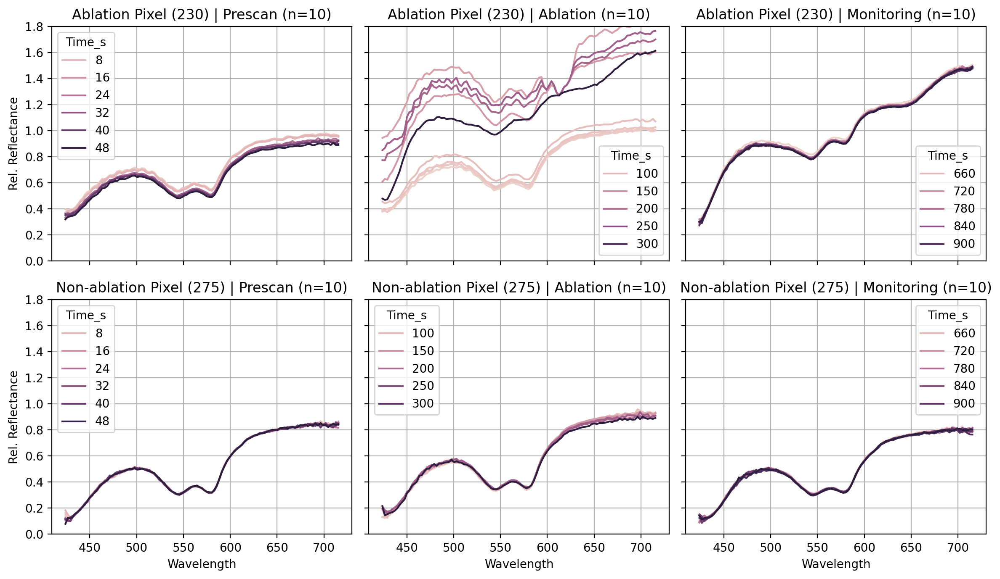

In [ ]:
n_group = 10

fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True, sharey=True)

# Ablation Pixel
x = abl
name = 'Ablation Pixel'

ax = axes[0, 0]
group = 'prescan'
df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120), n_group=n_group, long=True)
sns.lineplot(df[df['Phase'] == group], x='Wavelength', y='Intensity', hue='Time_s', ax=ax)
ax.set_title(f'{name} ({abl}) | {group.capitalize()} (n={n_group})')
ax.grid()
ax.set_ylim(0, 1.8)
ax.set_ylabel('Rel. Reflectance')

ax = axes[0, 1]
group = 'ablation'
df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120), n_group=n_group, long=True)
sns.lineplot(df[df['Phase'] == group], x='Wavelength', y='Intensity', hue='Time_s', ax=ax)
ax.set_title(f'{name} ({abl}) | {group.capitalize()} (n={n_group})')
ax.grid()
ax.set_ylim(0, 1.8)
ax.set_ylabel('Rel. Reflectance')

ax = axes[0, 2]
group = 'monitoring'
df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120), n_group=n_group, long=True)
sns.lineplot(df[df['Phase'] == group], x='Wavelength', y='Intensity', hue='Time_s', ax=ax)
ax.set_title(f'{name} ({abl}) | {group.capitalize()} (n={n_group})')
ax.grid()
ax.set_ylim(0, 1.8)
ax.set_ylabel('Rel. Reflectance')

# Non-ablation Pixel
x = nabl
name = 'Non-ablation Pixel'

ax = axes[1, 0]
group = 'prescan'
df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120), n_group=n_group, long=True)
sns.lineplot(df[df['Phase'] == group], x='Wavelength', y='Intensity', hue='Time_s', ax=ax)
ax.set_title(f'{name} ({nabl}) | {group.capitalize()} (n={n_group})')
ax.grid()
ax.set_ylim(0, 1.8)
ax.set_ylabel('Rel. Reflectance')

ax = axes[1, 1]
group = 'ablation'
df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120), n_group=n_group, long=True)
sns.lineplot(df[df['Phase'] == group], x='Wavelength', y='Intensity', hue='Time_s', ax=ax)
ax.set_title(f'{name} ({nabl}) | {group.capitalize()} (n={n_group})')
ax.grid()
ax.set_ylim(0, 1.8)
ax.set_ylabel('Rel. Reflectance')

ax = axes[1, 2]
group = 'monitoring'
df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120), n_group=n_group, long=True)
sns.lineplot(df[df['Phase'] == group], x='Wavelength', y='Intensity', hue='Time_s', ax=ax)
ax.set_title(f'{name} ({nabl}) | {group.capitalize()} (n={n_group})')
ax.grid()
ax.set_ylim(0, 1.8)
ax.set_ylabel('Rel. Reflectance')

fig.tight_layout()

filepath = analysis / f'Spectra_{smpl}_n{n_group}.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=200, bbox_inches='tight')
plt.show()

## Animation

In [ ]:
framestep = 1
duration_m = 3

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

df1 = get_spectra(cube, 'reflectance', abl, trim_bands=(10, 120))
data1 = df1.iloc[:, 3:].values
wvls1 = df1.iloc[:, 3:].columns.astype(float)
metadata1 = df1.iloc[:, :3].values

df2 = get_spectra(cube, 'reflectance', nabl, trim_bands=(10, 120))
data2 = df2.iloc[:, 3:].values
wvls2 = df2.iloc[:, 3:].columns.astype(float)
metadata2 = df2.iloc[:, :3].values

if len(data1) == len(data2):
  frames = range(0, len(data1), framestep)
else:
  raise ValueError('Data lengths do not match.')

fps = len(frames) / (duration_m * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Empty line that will be updated
ax = axes[0]
line1, = ax.plot(wvls1, data1[0], lw=2)
ax.set_xlim(wvls1.min(), wvls1.max())
ax.set_ylim(0, 2.1)
ax.set_xlabel("Wavelength")
ax.set_ylabel("Rel. Reflectance")

ax = axes[1]
line2, = ax.plot(wvls2, data2[0], lw=2)
ax.set_xlim(wvls2.min(), wvls2.max())
ax.set_ylim(0, 2.1)
ax.set_xlabel("Wavelength")
ax.set_ylabel("Rel. Reflectance")

def update(i):
  print(f'Updating frame {i}...')
  line1.set_data(wvls1, data1[i])
  line2.set_data(wvls2, data2[i])
  m, s = frame_to_time(i, frame_rate)
  axes[0].set_title(f"Ablation Pixel (x={abl}) | Time = {m:02d}:{s:02d} | {metadata1[i, 2].capitalize()}", loc='left', ha='left')
  axes[1].set_title(f"Non-Ablation Pixel (x={nabl}) | Time = {m:02d}:{s:02d} | {metadata2[i, 2].capitalize()}", loc='left', ha='left')

  return line1, line2

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,    # ms between frames
    blit=False
)

writer = FFMpegWriter(fps=fps, bitrate=3000)

# Save as mp4 (recommended)
ani.save(
    analysis / f"Progression_{smpl}.mp4",
    writer = writer,
    # fps=fps,
    dpi=200
)

plt.close(fig)

Updating frame 0...
Updating frame 0...
Updating frame 1...
Updating frame 2...
Updating frame 3...
Updating frame 4...
Updating frame 5...
Updating frame 6...
Updating frame 7...
Updating frame 8...
Updating frame 9...
Updating frame 10...
Updating frame 11...
Updating frame 12...
Updating frame 13...
Updating frame 14...
Updating frame 15...
Updating frame 16...
Updating frame 17...
Updating frame 18...
Updating frame 19...
Updating frame 20...
Updating frame 21...
Updating frame 22...
Updating frame 23...
Updating frame 24...
Updating frame 25...
Updating frame 26...
Updating frame 27...
Updating frame 28...
Updating frame 29...
Updating frame 30...
Updating frame 31...
Updating frame 32...
Updating frame 33...
Updating frame 34...
Updating frame 35...
Updating frame 36...
Updating frame 37...
Updating frame 38...
Updating frame 39...
Updating frame 40...
Updating frame 41...
Updating frame 42...
Updating frame 43...
Updating frame 44...
Updating frame 45...
Updating frame 46...
Upd

In [ ]:
  # VERSION 0

framestep = 1
duration_m = 3

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter

df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120))

data = df.iloc[:, 3:].values
wvls = df.iloc[:, 3:].columns.astype(float)
metadata = df.iloc[:, :3].values

frames = range(0, len(data), framestep)
fps = len(frames) / (duration_m * 60)

fig, ax = plt.subplots(figsize=(6, 4))

# Empty line that will be updated
line, = ax.plot([], [], lw=2)

ax.set_xlim(wvls.min(), wvls.max())
ax.set_ylim(0, 2.1)
ax.set_xlabel("Wavelength")
ax.set_ylabel("Intensity")

def update(i):
    spectrum = data[i]
    line.set_data(wvls, spectrum)
    m, s = frame_to_time(i, frame_rate)
    ax.set_title(f"{label} | Time = {m:02d}:{s:02d} | {metadata[i, 2].capitalize()}", loc='left', ha='left')

    return line,

ani = FuncAnimation(
    fig,
    update,
    frames=frames,
    interval=100,    # ms between frames
    blit=True
)

writer = FFMpegWriter(fps=fps, bitrate=3000)

# Save as mp4 (recommended)
ani.save(
    analysis / f"Progression_{sample}_{label}.mp4",
    writer = writer,
    # fps=fps,
    dpi=200
)

plt.close(fig)

In [ ]:
# df = get_spectra(cube, 'reflectance', x, trim_bands=(10, 120))
# data = df.iloc[:, 3:].values
# wvls = df.iloc[:, 3:].columns
# metadata = df.iloc[:, :3].values

# for i in range(0, len(df), 500):
# # for i in range(len(data)):
#   spectrum = data[i]
#   ax = sns.lineplot(x=wvls, y=spectrum, color=sns.color_palette()[0])
#   ax.set_ylim(0, 2.1)
#   ax.set_title(f'{label} | Time = {frame_to_time(i, frame_rate)[0]}:{frame_to_time(i, frame_rate)[1]} ({metadata[i, 2].capitalize()})')
#   plt.xlabel(f'Wavelength')
#   plt.ylabel(f'Intensity')
#   # plt.show()
#   filepath = folder / f'{i}.png'
#   print(f'Saving {filepath.stem}...')
#   plt.savefig(filepath, dpi=200, bbox_inches='tight')
#   plt.close()

Saving 0...
Saving 500...
Saving 1000...
Saving 1500...
Saving 2000...
Saving 2500...


In [ ]:
metadata

array([[0, 0, 'prescan'],
       [1, 0, 'prescan'],
       [2, 1, 'prescan'],
       ...,
       [2893, 961, 'monitoring'],
       [2894, 961, 'monitoring'],
       [2895, 962, 'monitoring']], dtype=object)

In [ ]:
len(df.columns)

113

# Slider

In [ ]:
def frame_to_time(frame, frame_rate):
  frame_time_s = frame * 1 / frame_rate
  frame_time_m = int(frame_time_s // 60)
  remaining_time_s = int(frame_time_s - frame_time_m * 60)
  return frame_time_m, remaining_time_s

In [ ]:
# # v1
# import ipywidgets as widgets
# import matplotlib.pyplot as plt
# from IPython.display import display

# from matplotlib.patches import Rectangle

# # cube.shape = (height, width, bands)

# def plot_spectrum(cube, x1, x2, timepoint):
#   fig, axes = plt.subplots(1, 2, figsize=(10, 5))

#   # RGB
#   ax = axes[0]
#   ax.imshow(cube.get_rgb(which_data='processed').rgb)
#   ax.scatter(x, timepoint, marker='+', color='red')
#   ax.set_ylabel('Timepoint (tp)')
#   ax.set_xlabel('Pixel (x)')
#   ax.set_title(f'RGB Rendering of HSI')

#   ax = axes[1]
#   ax.set_ylim((0, cube.processed.max()))
#   ax.plot(cube.processed[timepoint, x, :])
#   ax.set_xlabel("Band")
#   ax.set_ylabel("Intensity")
#   mm, ss = frame_to_time(timepoint, frame_rate)
#   ax.set_title(f"x = {x} | Time = {mm:02d}:{ss:02d}")
#   plt.grid(True)
#   plt.show()
#   plt.close()  # Clears the current figure from memory

In [ ]:
# # v2
# import ipywidgets as widgets
# import matplotlib.pyplot as plt
# from IPython.display import display

# from matplotlib.patches import Rectangle

# # cube.shape = (height, width, bands)

# def plot_spectrum(cube, x1, x2, timepoint):
#   fig, axes = plt.subplots(1, 3, figsize=(12, 5))

#   # RGB
#   ax = axes[0]
#   ax.set_ylim((0, 600))
#   ax.invert_yaxis()
#   ax.imshow(cube.get_rgb(which_data='processed').rgb)
#   ax.scatter(x1, timepoint, marker='+', color='green')
#   ax.scatter(x2, timepoint, marker='+', color='red')
#   ax.set_ylabel('Timepoint')
#   ax.set_xlabel('Pixel (x)')
#   ax.set_title(f'RGB Rendering of HSI')

#   ax = axes[1]
#   ax.set_ylim((0, cube.processed.max()))
#   ax.plot(cube.processed[timepoint, x1, :], color='green')
#   ax.set_xlabel("Band")
#   ax.set_ylabel("Intensity")
#   mm, ss = frame_to_time(timepoint, frame_rate)
#   ax.set_title(f"x1 = {x1} | Time = {mm:02d}:{ss:02d}")
#   ax.grid(True)
#   # plt.show()
#   # plt.close()  # Clears the current figure from memory

#   ax = axes[2]
#   ax.set_ylim((0, cube.processed.max()))
#   ax.plot(cube.processed[timepoint, x2, :], color='red')
#   ax.set_xlabel("Band")
#   ax.set_ylabel(None)
#   mm, ss = frame_to_time(timepoint, frame_rate)
#   ax.set_title(f"x2 = {x2} | Time = {mm:02d}:{ss:02d}")
#   ax.grid(True)

#   axes[2].sharex(axes[1])
#   axes[2].sharey(axes[1])

#   plt.tight_layout()

#   plt.show()
#   plt.close()  # Clears the current figure from memory

In [ ]:
# v3
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display

from matplotlib.patches import Rectangle

# cube.shape = (height, width, bands)

def plot_spectrum(cube, which_data, x1, x2, timepoint):
  fig, axes = plt.subplots(1, 3, figsize=(12, 5))

  # RGB
  ax = axes[0]
  ax.set_ylim((0, 600))
  ax.invert_yaxis()
  ax.imshow(cube.get_rgb(which_data='processed').rgb)
  ax.scatter(x1, timepoint, marker='+', color='green')
  ax.scatter(x2, timepoint, marker='+', color='red')
  ax.set_ylabel('Timepoint')
  ax.set_xlabel('Pixel (x)')
  ax.set_title(f'RGB Rendering of HSI')

  data = getattr(cube, which_data)

  ax = axes[1]
  ax.set_ylim((-5, +5))
  # ax.set_ylim((0, data.max()))
  ax.plot(data[timepoint, x1, 10:120], color='green')
  ax.set_xlabel("Band")
  ax.set_ylabel("Intensity")
  mm, ss = frame_to_time(timepoint, frame_rate)
  ax.set_title(f"x1 = {x1} | Time = {mm:02d}:{ss:02d}")
  ax.grid(True)
  # plt.show()
  # plt.close()  # Clears the current figure from memory

  ax = axes[2]
  ax.set_ylim((-5, +5))
  ax.plot(data[timepoint, x2, 10:120], color='red')
  ax.set_xlabel("Band")
  ax.set_ylabel(None)
  mm, ss = frame_to_time(timepoint, frame_rate)
  ax.set_title(f"x2 = {x2} | Time = {mm:02d}:{ss:02d}")
  ax.grid(True)

  axes[2].sharex(axes[1])
  axes[2].sharey(axes[1])

  plt.tight_layout()

  plt.show()
  plt.close()  # Clears the current figure from memory

In [ ]:
x1_val = 171
x2_val = 202

widgets.interact(
    plot_spectrum,
    cube=widgets.fixed(cube),  # Use fixed() for data arrays
    which_data=widgets.Dropdown(options=['processed', 'reflectance'], value='processed'),
    x1=widgets.IntSlider(min=0, max=cube.processed.shape[1] - 1, step=1, value=x1_val),
    x2=widgets.IntSlider(min=0, max=cube.processed.shape[1] - 1, step=1, value=x2_val),
    timepoint=widgets.IntSlider(min=0, max=cube.processed.shape[0] - 1, step=1, value=0),
)

interactive(children=(Dropdown(description='which_data', options=('processed', 'reflectance'), value='processe…

<function __main__.plot_spectrum(cube, which_data, x1, x2, timepoint)>

<Axes: >

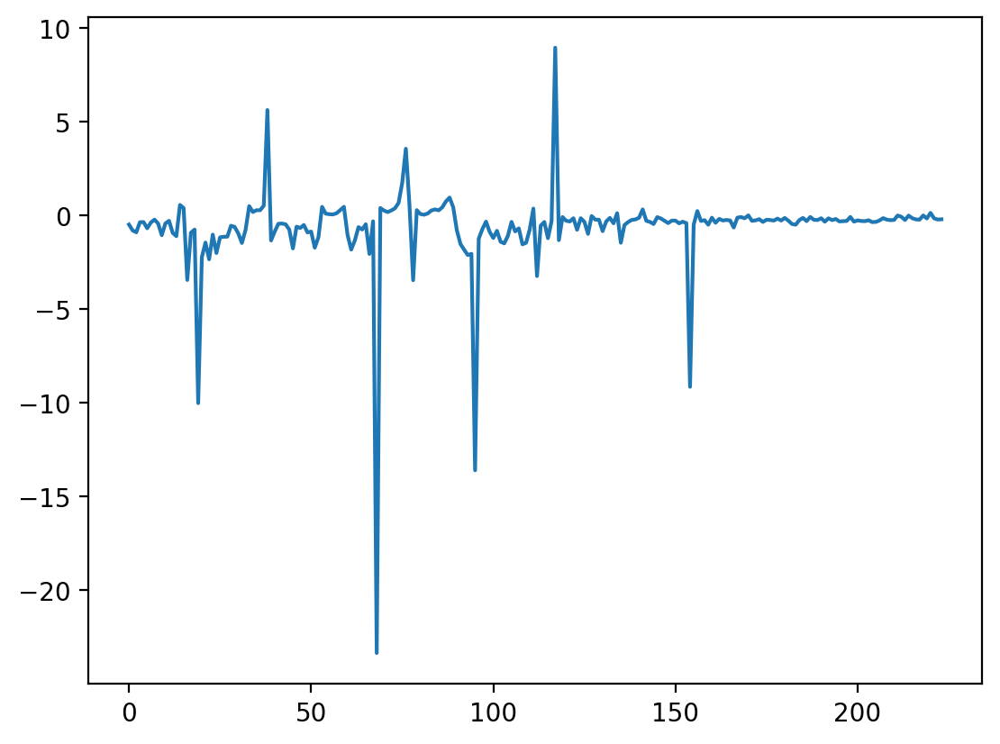

In [ ]:
x = 500
y = 700

spectrum = cube.reflectance[y:y+5, x:x+5, :].mean(axis=(0, 1))
sns.lineplot(spectrum)

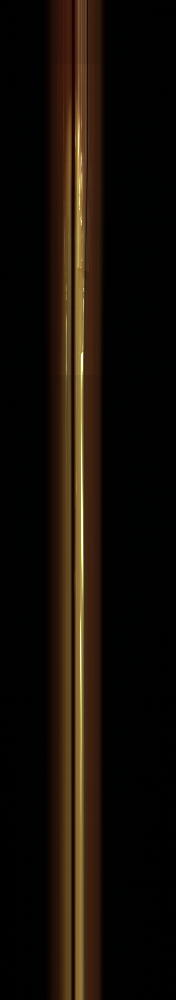

In [ ]:
cube.get_rgb(which_data='processed').rgb

In [ ]:
# v0
import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import display

# cube.shape = (height, width, bands)
cb = cube.processed

def plot_spectrum(cube, y, x):
  plt.figure(figsize=(6, 4))
  plt.plot(cube[y, x, :])
  plt.xlabel("Band")
  plt.ylabel("Intensity")
  plt.title(f"Pixel ({y}, {x})")
  plt.grid(True)
  plt.show()
  plt.close()  # Clears the current figure from memory

widgets.interact(
    plot_spectrum,
    cube=widgets.fixed(cb),  # Use fixed() for data arrays
    y=widgets.IntSlider(min=0, max=cb.shape[0] - 1, step=1, value=0),
    x=widgets.IntSlider(min=0, max=cb.shape[1] - 1, step=1, value=0),
)

interactive(children=(IntSlider(value=0, description='y', max=2898), IntSlider(value=0, description='x', max=5…

<function __main__.plot_spectrum(cube, y, x)>

In [ ]:
frame_to_time(cube.processed.shape[0], 3.01)

16:03


In [ ]:
frame_to_time(1, 3.01)

0.33222591362126247

In [ ]:
frames = cube.processed.shape[0]
total_time_s = frames * 1 / frame_rate
total_time_m = total_time_s / 60
print(total_time_m)

16.052048726467333


In [ ]:
(total_time_m % 16) * 60

3.1229235880400097

# ========= PREVIOUS DATASET (DELETE) =========

# RGBs

In [ ]:
folder = analysis / 'RGBs'
folder.mkdir(exist_ok=True)

In [ ]:
# data_path = dataset / 'HSI'

# cubenames = [path.name for path in data_path.glob('*')]

# for cubename in cubenames:
#   specbin = int(cubename.split('_')[-3].split('specbin')[1])
#   spatbin = int(cubename.split('_')[-2].split('spatbin')[1])

#   if (specbin >= 4) or (spatbin >= 4):
#     continue
#   cube = Cube(data_path / cubename).get_rgb()

#   darkpath = list(data_path.glob(f'dark_w_shutter*specbin{specbin}*spatbin{spatbin}*'))[0]
#   dark = Cube(darkpath)

#   cube.processed = cube.raw - np.mean(dark.raw, axis=0)
#   rgb = get_rgb(cube.processed, **cube.color_bands)

#   plt.figure(figsize=(12, 12))
#   plt.imshow(rgb)
#   plt.xlabel(f'Pixels')
#   plt.ylabel(f'Timepoint')
#   plt.title(f'{cube.name[:-5]} (- {dark.name[:-5]})')

#   filepath = folder / f'{cube.name[:-5]}.png'
#   print(f'Saving {filepath.stem}...')
#   plt.savefig(filepath, dpi=200, bbox_inches='tight')
#   plt.close()

/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


KeyboardInterrupt: 

---

# ROIs

In [ ]:
folder = analysis / 'ROIs'
folder.mkdir(exist_ok=True)

In [ ]:
# Coords with spatial binning of 8

x_ref, y_ref, width = 34, 10, 1

/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


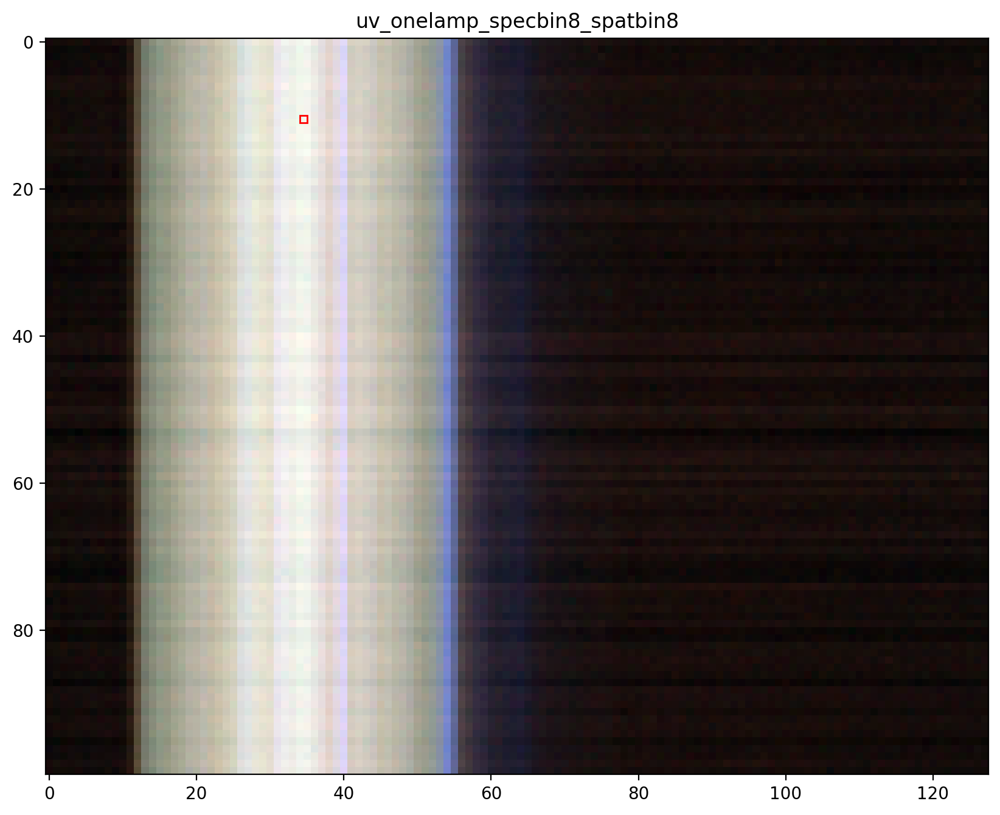

In [ ]:
from matplotlib.patches import Rectangle

specbin = 8
spatbin = 8

data_path = dataset / 'HSI'
cube_path = list(data_path.glob(f'uv*specbin{specbin}*spatbin{spatbin}*'))[0]
cube = Cube(cube_path)
dark = Cube(list(data_path.glob(f'dark_w_shutter*specbin{specbin}*spatbin{spatbin}*'))[0])
cube.processed = cube.raw - np.mean(dark.raw, axis=0)

cbands = bin_bands(cube.cbands, current_binning=1, target_binning=specbin)
cube.get_rgb(which_data='processed', color_bands=cbands)

plt.figure(figsize=(10, 10))
plt.title(f'{cube.name[:-5]}')
plt.imshow(cube.rgb)

x, _ = unbin_coord(x_ref, current_binning=8, target_binning=spatbin)
# plt.axvline(x)
rect = Rectangle((x, y_ref), width, width, linewidth=1, edgecolor='r', facecolor='none')
plt.gca().add_patch(rect)

In [ ]:
data_path = dataset / 'HSI'
cubenames = [path.name for path in data_path.glob('uv*')]

spectra = []
for cubename in cubenames:
  specbin = int(cubename.split('_')[-3].split('specbin')[1])
  spatbin = int(cubename.split('_')[-2].split('spatbin')[1])

  print(f'Doing specbin = {specbin}, spatbin = {spatbin}...')
  if (specbin == 4) and (spatbin == 1):
    print(f'  --> This one was skipped.')
    continue

  cube = Cube(data_path / cubename)
  dark = Cube(list(data_path.glob(f'dark_w_shutter*specbin{specbin}*spatbin{spatbin}*'))[0])
  cube.processed = cube.raw - np.mean(dark.raw, axis=0)
  cbands = bin_bands(cube.cbands, current_binning=1, target_binning=specbin)
  cube.get_rgb(which_data='processed', color_bands=cbands)

  # Coordinates
  x, _ = unbin_coord(x_ref, current_binning=8, target_binning=spatbin)
  # w = int(width * 8 / spatbin)
  w = 1

  # Plotting
  plt.figure(figsize=(12, 12))
  plt.imshow(cube.rgb)
  print(f'x = {x}, y = {y_ref}, w = {w}')
  rect = Rectangle((x, y_ref), w, 1, linewidth=1, edgecolor='r', facecolor='none')
  plt.gca().add_patch(rect)

  plt.xlabel(f'Pixels')
  plt.ylabel(f'Timepoint')
  plt.title(f'{cube.name[:-5]} (- {dark.name[:-5]})')

  filepath = folder / f'{cube.name[:-5]}.png'
  print(f'Saving {filepath.stem}...')
  plt.savefig(filepath, dpi=200, bbox_inches='tight')
  plt.close()

  # Spectra
  pixels = cube.processed[y_ref:y_ref+1, x:x+w, :]
  pixels = pixels.reshape(-1, pixels.shape[-1])
  pixels = pd.DataFrame(pixels, columns=cube.wvls)
  ids = pd.DataFrame({
      'cubename': cube.name[:-5],
      'specbin': specbin,
      'spatbin': spatbin,
      'lamps': cube.name.split('_')[1]
  }, index=range(len(pixels)))
  df = pd.concat([ids, pixels], axis=1)
  spectra.append(df)

spectra = pd.concat(spectra, axis=0)
spectra.reset_index(drop=True, inplace=True)
spectralong = spectra.melt(id_vars=['cubename', 'specbin', 'spatbin', 'lamps'], var_name='Wavelength', value_name='Intensity')

Doing specbin = 1, spatbin = 1...


/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


x = 272, y = 10, w = 1
Saving uv_onelamp_specbin1_spatbin1...
Doing specbin = 2, spatbin = 2...


/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


x = 136, y = 10, w = 1
Saving uv_onelamp_specbin2_spatbin2...
Doing specbin = 4, spatbin = 4...
x = 68, y = 10, w = 1
Saving uv_onelamp_specbin4_spatbin4...


/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


... (25 outputs left out)

/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


x = 136, y = 10, w = 1
Saving uv_onelampclose_specbin1_spatbin2...
Doing specbin = 2, spatbin = 2...


/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


x = 136, y = 10, w = 1
Saving uv_onelampclose_specbin2_spatbin2...


Text(0, 0.5, 'Intensity')

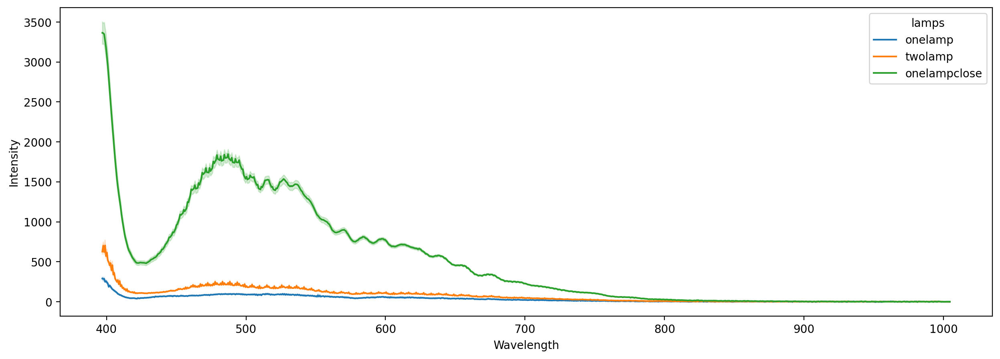

In [ ]:
plt.figure(figsize=(15, 5))
sns.lineplot(spectralong, x='Wavelength', y='Intensity', hue='lamps')
plt.xlabel(f'Wavelength')
plt.ylabel(f'Intensity')

Saving Spectra_hue_cubename_style_lamps_woclose...


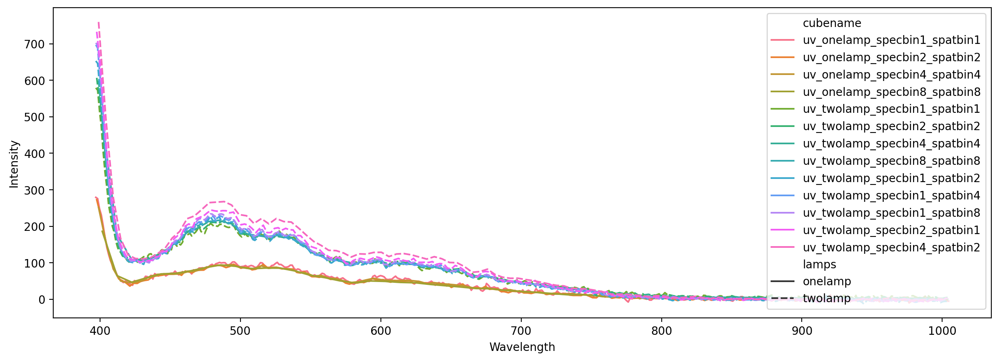

In [ ]:
plt.figure(figsize=(15, 5))
df = spectralong[spectralong['lamps'] != 'onelampclose']
sns.lineplot(df, x='Wavelength', y='Intensity', hue='cubename', style='lamps', errorbar=None)
plt.xlabel(f'Wavelength')
plt.ylabel(f'Intensity')

filepath = analysis / f'Spectra_hue_cubename_style_lamps_woclose.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
spectralong.cubename.unique()

array(['uv_onelamp_specbin1_spatbin1', 'uv_onelamp_specbin2_spatbin2',
       'uv_onelamp_specbin4_spatbin4', 'uv_onelamp_specbin8_spatbin8',
       'uv_twolamp_specbin1_spatbin1', 'uv_twolamp_specbin2_spatbin2',
       'uv_twolamp_specbin4_spatbin4', 'uv_twolamp_specbin8_spatbin8',
       'uv_twolamp_specbin1_spatbin2', 'uv_twolamp_specbin1_spatbin4',
       'uv_twolamp_specbin1_spatbin8', 'uv_twolamp_specbin2_spatbin1',
       'uv_twolamp_specbin4_spatbin2',
       'uv_onelampclose_specbin1_spatbin1',
       'uv_onelampclose_specbin2_spatbin1',
       'uv_onelampclose_specbin1_spatbin2',
       'uv_onelampclose_specbin2_spatbin2'], dtype=object)

# Software vs. Hardware Binning

In [ ]:
import numpy as np

def bin_cube(cube, y_factor=1, x_factor=1, lambda_factor=1):
    """
    Bin a hyperspectral cube by averaging.

    Parameters
    ----------
    cube : ndarray
        Input cube of shape (y, x, wavelength).
    y_factor : int
        Binning factor along y.
    x_factor : int
        Binning factor along x.
    lambda_factor : int
        Binning factor along wavelength.

    Returns
    -------
    ndarray
        Binned cube.
    """
    y, x, l = cube.shape

    if y % y_factor != 0:
        raise ValueError(f"y dimension ({y}) is not divisible by {y_factor}")
    if x % x_factor != 0:
        raise ValueError(f"x dimension ({x}) is not divisible by {x_factor}")
    if l % lambda_factor != 0:
        raise ValueError(f"wavelength dimension ({l}) is not divisible by {lambda_factor}")

    return cube.reshape(
        y // y_factor, y_factor,
        x // x_factor, x_factor,
        l // lambda_factor, lambda_factor
    ).mean(axis=(1, 3, 5))

In [ ]:
# dataset specific function
def get_cube(specbin, spatbin):
  data_path = dataset / 'HSI'
  cube_path = list(data_path.glob(f'uv*specbin{specbin}*spatbin{spatbin}*'))[0]
  cube = Cube(cube_path)
  print(f'Cube read: {cube.name}')
  dark = Cube(list(data_path.glob(f'dark_w_shutter*specbin{specbin}*spatbin{spatbin}*'))[0])
  print(f'Dark read: {dark.name}')
  cube.processed = cube.raw - np.mean(dark.raw, axis=0)

  cbands = bin_bands(cube.cbands, current_binning=1, target_binning=specbin)
  cube.get_rgb(which_data='processed', color_bands=cbands)
  return cube

In [ ]:
list(data_path.glob('uv*specbin1*'))

[PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_onelamp_specbin1_spatbin1_0005'),
 PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_twolamp_specbin1_spatbin1_0019'),
 PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_twolamp_specbin1_spatbin2_0023'),
 PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_twolamp_specbin1_spatbin4_0024'),
 PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_twolamp_specbin1_spatbin8_0026'),
 PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_onelampclose_specbin1_spatbin1_0036'),
 PosixPath('/content/drive/MyDrive/DATA/PROJECTS/NCDC/260727_Spectral_Spatial_Binning_Test/HSI/uv_onelampclose_specbin1_spatbin2_0039')]

In [ ]:
x_ref, y_ref, width = 34, 10, 1

In [ ]:
spatbin = 8
binned = get_cube(specbin=1, spatbin=spatbin)

cube = get_cube(specbin=1, spatbin=1)
cube.justbinned = bin_cube(cube.processed, y_factor=1, x_factor=spatbin, lambda_factor=1)
cube.get_rgb(which_data='justbinned', color_bands=cube.cbands)

Cube read: uv_twolamp_specbin1_spatbin8_0026
Dark read: dark_w_shutter_specbin1_spatbin8_0033
Cube read: uv_onelamp_specbin1_spatbin1_0005
Dark read: dark_w_shutter_specbin1_spatbin1_0004


Saving Hardware_vs_Software_Binning...


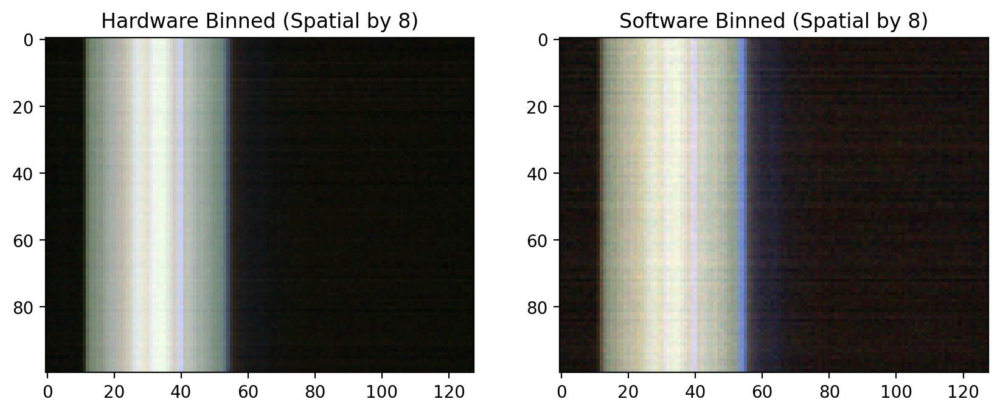

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.set_title(f'Hardware Binned (Spatial by 8)')
ax.imshow(binned.rgb)

ax = axes[1]
ax.set_title(f'Software Binned (Spatial by 8)')
ax.imshow(cube.rgb)

filepath = analysis / 'Hardware_vs_Software_Binning.png'
print(f'Saving {filepath.stem}...')
plt.savefig(filepath, dpi=300, bbox_inches='tight')
plt.show()

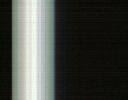

In [ ]:
binned.rgb

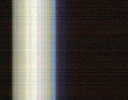

In [ ]:
cube.rgb

In [ ]:
cube.get_rg

/usr/local/lib/python3.12/dist-packages/spectral/io/envi.py:187: UserWarning: Parameters with non-lowercase names encountered and converted to lowercase. To retain source file parameter name capitalization, set spectral.settings.envi_support_nonlowercase_params to True.
  warnings.warn(msg)


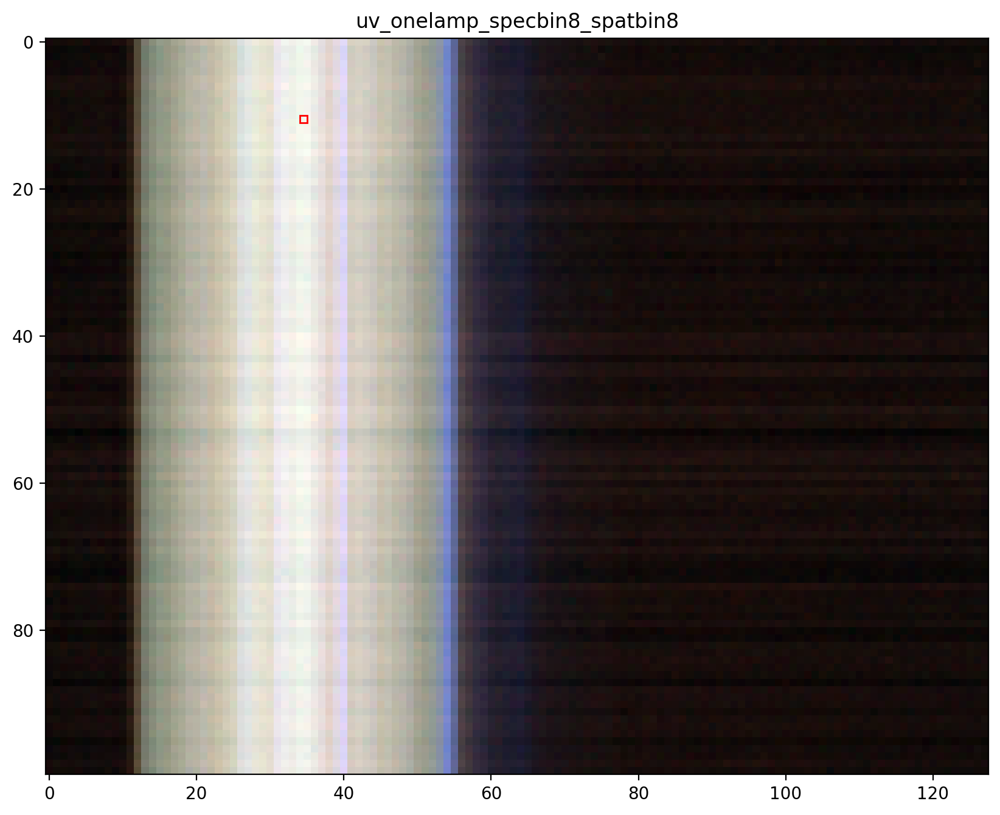

In [ ]:
from matplotlib.patches import Rectangle

specbin = 8
spatbin = 8

cube = get_cube(specbin, spatbin)

plt.figure(figsize=(10, 10))
plt.title(f'{cube.name[:-5]}')
plt.imshow(cube.rgb)

x, _ = unbin_coord(x_ref, current_binning=8, target_binning=spatbin)
rect = Rectangle((x, y_ref), width, 1, linewidth=1, edgecolor='r', facecolor='none')
plt.gca().add_patch(rect)

In [ ]:
import sys

print(f"Size of 'data' variable: {sys.getsizeof(data) / (1024**2):.2f} MB")
print(f"Size of 'mean_frame' variable: {sys.getsizeof(mean_frame) / (1024**2):.2f} MB")

Size of 'data' variable: 4887.00 MB
Size of 'mean_frame' variable: 1.69 MB


The `data` variable is a NumPy array of shape (576, 768, 2896) with `float32` data type, which means it occupies approximately 5.9 GB of RAM. The `mean_frame` variable is a NumPy array of shape (576, 768) and occupies approximately 1.7 MB of RAM. The `data` variable is taking up the majority of the RAM in the current notebook.